# Singapore COE Price Convergence and Category Policy

**Team:** Godex | SDS Mini Datathon 2026

**Members:** Eng Cheng Xin, Eugene Poon Wen Teng, Lew Wai Loon (Austin), Wong E Shen

An integrated analysis of A/B premium separation, registration mix, listed vehicle values, conditional forecasts and illustrative merger/feebate outcomes. Historical numerical coverage ends in October 2026.

## 1. Setup & Imports

The analysis uses Python 3.14. Fixed random seeds make model fitting and plot jitter reproducible. Package versions are recorded below and specified in `requirements.txt`.

In [2]:
import sys
import random
from datetime import timedelta
from copy import deepcopy
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator, StrMethodFormatter
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from lightgbm import LGBMRegressor
from skforecast.recursive import ForecasterRecursiveMultiSeries
from skforecast.model_selection import TimeSeriesFold, backtesting_forecaster_multiseries

In [3]:
if sys.version_info[:2] != (3, 14):
    raise RuntimeError("This notebook requires Python 3.14.")
print(f"Python version: {sys.version.split()[0]}")

packages = ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn",
            "lightgbm", "skforecast", "ipython"]
package_versions = pd.DataFrame({
    "package": packages,
    "version": [version(package) for package in packages],
})
display(package_versions)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titlesize": 12,
                     "axes.labelsize": 10, "figure.facecolor": "white"})

Python version: 3.14.2


,package,version
0,numpy,2.5.4
1,pandas,2.3.3
2,matplotlib,3.11.2
3,seaborn,0.13.2
4,scikit-learn,1.9.1
5,lightgbm,4.7.0
6,skforecast,0.26.0
7,ipython,9.17.1


## 2. Data Ingestion

The analysis uses three local datasets:

- **COE bidding results:** premiums, quotas and bid counts for each category and bidding exercise, January 2010-October 2026.
- **Car registrations:** reported counts by month, make, importer type, fuel type and vehicle type, January 2016-May 2025. These records do not identify models or COE categories.
- **September 2026 car cost update:** listed model entries with COE categories and average open market values (OMVs). This snapshot contains no registration counts, so comparisons give each listed entry equal weight.

COE analyses are not restricted to registration coverage. Registration comparisons use their own overlapping period. The OMV snapshot is analysed separately; it is not joined to monthly registrations.

In [4]:
DATA_DIR = Path("data")
data_files = {
    "COE bidding": DATA_DIR / "COEBiddingResultsPrices.csv",
    "Car registrations": DATA_DIR / "NewRegistrationofCarsbyMake.csv",
    "September OMV snapshot": DATA_DIR / "M032-Car_Cost_Update_Sep_2026.csv",
}
for dataset, file_path in data_files.items():
    if not file_path.is_file():
        raise FileNotFoundError(f"{dataset}: missing {file_path}")

coe_raw = pd.read_csv(data_files["COE bidding"], dtype="string")
registrations_raw = pd.read_csv(data_files["Car registrations"], dtype="string")
car_costs_raw = pd.read_csv(data_files["September OMV snapshot"], dtype="string")
OMV_SNAPSHOT_MONTH = pd.Timestamp("2026-09-01")

data_inventory = pd.DataFrame([
    {"dataset": "COE bidding", "rows": len(coe_raw), "columns": coe_raw.shape[1],
     "first_month": coe_raw["month"].min(), "last_month": coe_raw["month"].max(),
     "observation": "Category within a bidding exercise"},
    {"dataset": "Car registrations", "rows": len(registrations_raw),
     "columns": registrations_raw.shape[1],
     "first_month": registrations_raw["month"].min(),
     "last_month": registrations_raw["month"].max(),
     "observation": "Month / make / importer / fuel / vehicle type"},
    {"dataset": "September OMV snapshot", "rows": len(car_costs_raw),
     "columns": car_costs_raw.shape[1],
     "first_month": OMV_SNAPSHOT_MONTH.strftime("%Y-%m"),
     "last_month": OMV_SNAPSHOT_MONTH.strftime("%Y-%m"),
     "observation": "Listed model entry"},
])
display(data_inventory)

,dataset,rows,columns,first_month,last_month,observation
0,COE bidding,1990,7,2010-01,2026-10,Category within a bidding exercise
1,Car registrations,51669,6,2016-01,2025-05,Month / make / importer / fuel / vehicle type
2,September OMV snapshot,237,22,2026-09,2026-09,Listed model entry


In [5]:
display(coe_raw.head(3))
display(registrations_raw.head(3))
display(car_costs_raw[["SN", "Make", "Model", "COE Category", "Average OMV (S$)"]].head(3))

,month,bidding_no,vehicle_class,quota,bids_success,bids_received,premium
0,2010-01,1,Category A,1152,1145,1342,18502
1,2010-01,1,Category B,687,679,883,19190
2,2010-01,1,Category C,173,173,265,19001


,month,make,importer_type,fuel_type,vehicle_type,number
0,2016-01,ALFA ROMEO,<NA>,Petrol,Hatchback,3
1,2016-01,ALPINA,<NA>,Petrol,Hatchback,0
2,2016-01,ASTON MARTIN,<NA>,Petrol,Hatchback,0


,SN,Make,Model,COE Category,Average OMV (S$)
0,1,AUDI,A3 SEDAN S LINE 1.5 TFSI (85 KW),A,25626
1,2,AUDI,A3 SPORTBACK S LINE 1.5 TFSI (85 KW),A,27079
2,3,AUDI,A5 SEDAN TFSI 150 KW,B,38780


## 3. Data Cleaning

Preserve the imported tables and prepare separate cleaned copies. Remove identical rows, convert numeric fields and dates, and check record keys and valid ranges. Invalid required values stop the analysis. Missing observations are not interpolated.

### 3.1 COE bidding results

**Reason:** Text-formatted bid counts must be numeric before calculating bidding pressure. Each exercise must have one valid record for every category before A and B can be paired. Retain the full COE history, including the absence of bidding records in April-June 2020.

In [6]:
def clean_numeric(series, label, allow_missing=False):
    text = series.astype("string").str.strip().str.replace(r"[, ]", "", regex=True)
    text = text.replace("", pd.NA)
    values = pd.to_numeric(text, errors="raise")
    if not allow_missing and values.isna().any():
        raise ValueError(f"Missing required numeric values: {label}")
    if not np.isfinite(values.dropna().to_numpy(dtype=float)).all():
        raise ValueError(f"Non-finite numeric values: {label}")
    return values


coe_identical_removed = int(coe_raw.duplicated().sum())
coe = coe_raw.drop_duplicates().copy()
coe["month"] = pd.to_datetime(coe["month"].str.strip(), format="%Y-%m", errors="raise")
coe["vehicle_class"] = coe["vehicle_class"].str.strip()
coe_numeric_columns = ["bidding_no", "quota", "bids_success", "bids_received", "premium"]
for column in coe_numeric_columns:
    values = clean_numeric(coe[column], f"COE {column}")
    assert values.mod(1).eq(0).all(), f"Non-integer COE values: {column}"
    coe[column] = values.astype("int64")
coe = coe.sort_values(["month", "bidding_no", "vehicle_class"]).reset_index(drop=True)

coe_key = ["month", "bidding_no", "vehicle_class"]
expected_categories = {f"Category {letter}" for letter in "ABCDE"}
assert coe[coe_key + coe_numeric_columns[1:]].notna().all().all(), "Missing required COE values."
assert not coe.duplicated(coe_key).any(), "Duplicate COE exercise/category keys."
assert set(coe["vehicle_class"]) == expected_categories, "Unexpected COE categories."
assert coe["bidding_no"].isin([1, 2]).all(), "Unexpected bidding exercise number."
assert coe[coe_numeric_columns].ge(0).all().all(), "Negative COE values."
assert coe["quota"].gt(0).all(), "Quotas must be positive."
assert coe["premium"].gt(0).all(), "Premiums must be positive."
assert coe["bids_success"].le(coe["quota"]).all(), "Successful bids exceed quota."
assert coe["bids_success"].le(coe["bids_received"]).all(), "Successful bids exceed bids received."

coe_exercises = coe.groupby(["month", "bidding_no"])["vehicle_class"].nunique()
assert coe_exercises.eq(5).all(), "Incomplete category coverage within an exercise."
coe_calendar_months = pd.date_range(coe["month"].min(), coe["month"].max(), freq="MS")
missing_coe_months = coe_calendar_months.difference(pd.DatetimeIndex(coe["month"].unique()))
coe_validation_summary = pd.DataFrame([{
    "rows": len(coe), "bidding_exercises": len(coe_exercises),
    "observed_months": coe["month"].nunique(),
    "first_month": coe["month"].min().strftime("%Y-%m"),
    "last_month": coe["month"].max().strftime("%Y-%m"),
    "absent_months": ", ".join(missing_coe_months.strftime("%Y-%m")),
}])
display(coe_validation_summary)

,rows,bidding_exercises,observed_months,first_month,last_month,absent_months
0,1990,398,199,2010-01,2026-10,"2020-04, 2020-05, 2020-06"


The cleaned COE table contains **398 exercises across 199 observed months**. April-June 2020 remains absent. `month` identifies the calendar month and `bidding_no` the exercise order; neither supplies the exact auction date.

### 3.2 Car registrations

**Reason:** A blank registration count is unknown, whereas zero is an explicitly reported count. Keep both distinct, retain missing importer types and normalise make names for consistent brand grouping. Reported-count shares may be incomplete and cannot be interpreted as COE-category shares.

In [7]:
registrations_identical_removed = int(registrations_raw.duplicated().sum())
registrations = registrations_raw.drop_duplicates().copy()
registrations["month"] = pd.to_datetime(
    registrations["month"].str.strip(), format="%Y-%m", errors="raise"
)
registration_labels = ["make", "importer_type", "fuel_type", "vehicle_type"]
for column in registration_labels:
    registrations[column] = registrations[column].str.strip()
registration_counts = clean_numeric(registrations["number"], "registration number", allow_missing=True)
assert registration_counts.dropna().ge(0).all(), "Negative registration counts."
assert registration_counts.dropna().mod(1).eq(0).all(), "Non-integer registration counts."
registrations["number"] = registration_counts.astype("Int64")

registration_key = ["month", "make", "importer_type", "fuel_type", "vehicle_type"]
assert registrations[["month", "make", "fuel_type", "vehicle_type"]].notna().all().all(), "Missing registration labels."
assert not registrations.duplicated(registration_key).any(), "Duplicate registration record keys."
registrations["make_normalised"] = (
    registrations["make"].str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
)
registrations = registrations.sort_values(registration_key, na_position="last").reset_index(drop=True)

registration_validation_summary = pd.DataFrame([{
    "rows": len(registrations),
    "first_month": registrations["month"].min().strftime("%Y-%m"),
    "last_month": registrations["month"].max().strftime("%Y-%m"),
    "unknown_counts_retained": int(registrations["number"].isna().sum()),
    "zero_counts_retained": int(registrations["number"].eq(0).sum()),
    "missing_importer_types_retained": int(registrations["importer_type"].isna().sum()),
}])
display(registration_validation_summary)

,rows,first_month,last_month,unknown_counts_retained,zero_counts_retained,missing_importer_types_retained
0,51669,2016-01,2025-05,29463,6390,31155


### 3.3 September 2026 OMV snapshot

**Reason:** Compare valid listed entries without treating repeated make/model labels as duplicate vehicles. Separate entries can have different reported values, so retain them and validate the source row identifier instead. Missing engine capacities and selling prices remain missing; they are not required for the OMV comparison. Registration counts are unavailable, so no sales weights are assigned.

In [8]:
car_costs_identical_removed = int(car_costs_raw.duplicated().sum())
car_costs = car_costs_raw.drop_duplicates().copy()
car_cost_labels = ["Make", "Model", "COE Category", "Fuel Type", "VES Banding"]
for column in car_cost_labels:
    car_costs[column] = car_costs[column].str.strip()
car_cost_numeric_columns = [column for column in car_costs if column not in car_cost_labels]
for column in car_cost_numeric_columns:
    car_costs[column] = clean_numeric(car_costs[column], f"car cost {column}", allow_missing=True)

omv_col = "Average OMV (S$)"
omv_required = ["SN", "Make", "Model", "COE Category", omv_col, "Max Power Output (kW)"]
assert car_costs[omv_required].notna().all().all(), "Missing required OMV snapshot values."
assert car_costs["SN"].mod(1).eq(0).all() and car_costs["SN"].gt(0).all(), "Invalid source row identifiers."
car_costs["SN"] = car_costs["SN"].astype("int64")
assert car_costs["SN"].is_unique, "Duplicate source row identifiers in the OMV snapshot."
assert car_costs["COE Category"].isin(["A", "B"]).all(), "Unexpected OMV snapshot category."
assert car_costs[omv_col].gt(0).all(), "OMV values must be positive."
assert car_costs["Max Power Output (kW)"].gt(0).all(), "Power values must be positive."
assert car_costs["CO2 (g/km)"].dropna().ge(0).all(), "Negative CO2 values."
assert car_costs["Engine Capacity (cc)"].dropna().ge(0).all(), "Negative engine capacities."
car_costs = car_costs.sort_values("SN").reset_index(drop=True)
ab_models = car_costs.loc[car_costs["COE Category"].isin(["A", "B"])].copy()

omv_validation_summary = pd.DataFrame([{
    "snapshot_month": OMV_SNAPSHOT_MONTH.strftime("%Y-%m"),
    "listed_entries": len(ab_models),
    "A_entries": int(ab_models["COE Category"].eq("A").sum()),
    "B_entries": int(ab_models["COE Category"].eq("B").sum()),
    "missing_omv": int(ab_models[omv_col].isna().sum()),
    "repeated_make_model_category_labels_retained": int(
        ab_models.duplicated(["Make", "Model", "COE Category"]).sum()
    ),
}])
display(omv_validation_summary)

,snapshot_month,listed_entries,A_entries,B_entries,missing_omv,repeated_make_model_category_labels_retained
0,2026-09,237,100,137,0,4


### 3.4 Paired A/B bidding table

**Reason:** Pair A and B from the same month and exercise to compare premiums consistently. Positive signed gaps mean B costs more; negative gaps mean A costs more. Absolute gaps measure separation without reversals cancelling. Percentage gaps use B's premium as the denominator. Bids per quota describe observed competition after each exercise closes.

In [9]:
coe_ab = coe.loc[coe["vehicle_class"].isin(["Category A", "Category B"])].copy()
coe_ab["category"] = coe_ab["vehicle_class"].map({"Category A": "a", "Category B": "b"})
paired_metrics = ["premium", "quota", "bids_success", "bids_received"]

ab_trends = coe_ab.pivot(
    index=["month", "bidding_no"], columns="category", values=paired_metrics
)
ab_trends.columns = [f"{metric}_{category}" for metric, category in ab_trends.columns]
ab_trends = ab_trends.reset_index().sort_values(["month", "bidding_no"]).reset_index(drop=True)
assert len(ab_trends) == len(coe_exercises), "A/B pairing lost exercises."
assert ab_trends.notna().all().all(), "An A/B pair is incomplete."

ab_trends["gap_sgd"] = ab_trends["premium_b"] - ab_trends["premium_a"]
ab_trends["gap_pct_of_b"] = ab_trends["gap_sgd"] / ab_trends["premium_b"] * 100
ab_trends["abs_gap_sgd"] = ab_trends["gap_sgd"].abs()
ab_trends["abs_gap_pct_of_b"] = ab_trends["gap_pct_of_b"].abs()
ab_trends["a_exceeds_b"] = ab_trends["premium_a"] > ab_trends["premium_b"]
ab_trends["a_at_least_b"] = ab_trends["premium_a"] >= ab_trends["premium_b"]
for category in ["a", "b"]:
    ab_trends[f"bids_to_quota_{category}"] = (
        ab_trends[f"bids_received_{category}"] / ab_trends[f"quota_{category}"]
    )

ab_trends.head()

,month,bidding_no,premium_a,premium_b,quota_a,quota_b,bids_success_a,bids_success_b,bids_received_a,bids_received_b,gap_sgd,gap_pct_of_b,abs_gap_sgd,abs_gap_pct_of_b,a_exceeds_b,a_at_least_b,bids_to_quota_a,bids_to_quota_b
0,2010-01-01,1,18502,19190,1152,687,1145,679,1342,883,688,3.585201,688,3.585201,False,False,1.164931,1.285298
1,2010-01-01,2,20501,22400,1151,717,1149,717,1673,1105,1899,8.477679,1899,8.477679,False,False,1.453519,1.541144
2,2010-02-01,1,19989,23180,1154,1154,1153,690,1326,930,3191,13.766178,3191,13.766178,False,False,1.149047,0.805893
3,2010-02-01,2,20340,23889,1148,685,1148,658,1493,956,3549,14.856210,3549,14.856210,False,False,1.300523,1.395620
4,2010-03-01,1,20802,26389,1148,688,1141,667,1758,1087,5587,21.171700,5587,21.171700,False,False,1.531359,1.579942


The paired table retains all **398 observed exercises**. COE trends and forecasts are not shortened to the registration overlap. Registration comparisons cover **January 2016-May 2025**, with unavailable observations left missing. The September 2026 OMV snapshot remains separate from both time series.

In [10]:
cleaning_summary = pd.DataFrame([
    {"dataset": "COE bidding", "identical_rows_removed": coe_identical_removed,
     "cleaned_rows": len(coe)},
    {"dataset": "Car registrations", "identical_rows_removed": registrations_identical_removed,
     "cleaned_rows": len(registrations)},
    {"dataset": "September OMV snapshot", "identical_rows_removed": car_costs_identical_removed,
     "cleaned_rows": len(car_costs)},
])
display(cleaning_summary)

,dataset,identical_rows_removed,cleaned_rows
0,COE bidding,0,1990
1,Car registrations,0,51669
2,September OMV snapshot,0,237


### 3.5 Monthly registrations and A/B pressure

**Reason:** Aggregate counts by month and fuel/make before joining to monthly
bidding pressure. Reindex all measures to the full calendar before shifts and
differences. Retain all-missing subtotals as missing and cast aggregated counts
to ordinary floats for consistent pandas arithmetic. Pressure is the monthly
mean of round-level bids/quota. The luxury proxy is an analytical grouping of
selected makes, rather than an official vehicle-value classification.

In [11]:
market_start = max(coe["month"].min(), registrations["month"].min())
market_end = min(coe["month"].max(), registrations["month"].max())
market_calendar = pd.date_range(market_start, market_end, freq="MS")
market_reg = registrations.loc[registrations["month"].between(market_start, market_end)].copy()
market_coe_ab = coe.loc[
    coe["month"].between(market_start, market_end)
    & coe["vehicle_class"].isin(["Category A", "Category B"])
].copy()
market_coe_ab["bids_to_quota"] = market_coe_ab["bids_received"] / market_coe_ab["quota"]
market_ab_pressure = (
    market_coe_ab.groupby(["month", "vehicle_class"])["bids_to_quota"]
    .mean().unstack("vehicle_class").reindex(market_calendar)
)
market_reported_total = (
    market_reg.groupby("month")["number"].sum(min_count=1)
    .reindex(market_calendar).astype(float).rename("reported_total")
)
market_fuel_counts = (
    market_reg.groupby(["month", "fuel_type"])["number"].sum(min_count=1)
    .unstack("fuel_type").reindex(market_calendar).astype(float)
)
market_make_counts = (
    market_reg.groupby(["month", "make_normalised"])["number"].sum(min_count=1)
    .unstack("make_normalised").reindex(market_calendar).astype(float)
)
assert market_reported_total.dropna().gt(0).all()
market_fuel_shares = market_fuel_counts.div(market_reported_total, axis=0)
market_make_shares = market_make_counts.div(market_reported_total, axis=0)
LUXURY_PROXY_MAKES = {
    "AUDI", "BMW", "MERCEDESBENZ", "PORSCHE", "JAGUAR", "LANDROVER", "VOLVO",
    "BENTLEY", "ROLLSROYCE", "FERRARI", "LAMBORGHINI", "MASERATI", "MCLAREN", "ASTONMARTIN",
}
market_luxury_count = (
    market_reg.loc[market_reg["make_normalised"].isin(LUXURY_PROXY_MAKES)]
    .groupby("month")["number"].sum(min_count=1).reindex(market_calendar).astype(float)
)
registration_monthly = pd.DataFrame({
    "reported_total": market_reported_total,
    "electric_count": market_fuel_counts["Electric"],
    "luxury_proxy_count": market_luxury_count,
})
registration_monthly["electric_reported_share"] = market_fuel_shares["Electric"]
registration_monthly["luxury_proxy_reported_share"] = (
    registration_monthly["luxury_proxy_count"] / market_reported_total
)
market = registration_monthly.join(market_ab_pressure.rename(columns={
    "Category A": "Category_A_bids_to_quota", "Category B": "Category_B_bids_to_quota",
}))
market.index.name = "month"
market["previous_month_electric_share"] = market["electric_reported_share"].shift(1)
market["previous_month_luxury_share"] = market["luxury_proxy_reported_share"].shift(1)
market_correlation_rows = []
for label, share_column in [
    ("Prior-month pure-EV share", "previous_month_electric_share"),
    ("Prior-month luxury-proxy share", "previous_month_luxury_share"),
]:
    pairs = market[[share_column, "Category_A_bids_to_quota"]].dropna()
    assert len(pairs) >= 3
    market_correlation_rows.append({
        "registration_measure": label,
        "first_pressure_month": pairs.index.min().strftime("%Y-%m"),
        "last_pressure_month": pairs.index.max().strftime("%Y-%m"),
        "paired_months": len(pairs),
        "pearson_r": pairs[share_column].corr(pairs["Category_A_bids_to_quota"]),
    })
market_correlation_summary = pd.DataFrame(market_correlation_rows)
assert market_ab_pressure.loc["2020-04-01":"2020-06-01"].isna().all().all()
assert market_ab_pressure.diff().loc["2020-07-01"].isna().all()

## 4. Exploratory Data Analysis

Examine A/B price ordering, changes in category eligibility and changes in reported fuel/make shares and their associations with A/B bidding pressure. Keep COE prices, vehicle values and assumed merger outcomes distinct when interpreting the evidence.

### 4.1 Measures

| Measure | Definition and interpretation |
| --- | --- |
| COE premium | The category's reported premium for a bidding exercise, in S$. It is not the total car price. |
| Signed premium gap | B premium minus A premium. Positive means B costs more; negative means A costs more. |
| Absolute percentage gap | Absolute value of the signed gap, divided by B's premium, multiplied by 100. Smaller values indicate closer COE prices. |
| A/B bidding pressure | Bids received divided by quota for each exercise. Monthly pressure is the average of these exercise-level ratios, rather than a ratio of monthly totals. |
| Reported registration share | Reported counts for a selected fuel or make group divided by all reported counts in that month. Unknown counts remain excluded from both sums; the result may not represent the full market. |
| Listed OMV | The average OMV reported for each listed model entry in September 2026. Category comparisons give each entry equal weight, without registration weighting. |
| Feebate cost change | Assumed merged premium plus a signed adjustment, minus the existing category premium. Rebates are negative adjustments, surcharges positive; a negative cost change indicates savings. |

### 4.2 Price ordering and policy context

Use all 398 observed A/B pairs from January 2010 to October 2026. The latest exercise illustrates current closeness; a single observation cannot establish how long it will persist.

In [12]:
trend_history = ab_trends.sort_values(["month", "bidding_no"]).reset_index(drop=True).copy()
trend_latest_exercise = trend_history.tail(1)[[
    "month", "bidding_no", "premium_a", "premium_b", "gap_sgd", "gap_pct_of_b"
]].copy()
trend_latest_exercise["month"] = trend_latest_exercise["month"].dt.strftime("%Y-%m")
display(trend_latest_exercise.round({"gap_pct_of_b": 3}))

,month,bidding_no,premium_a,premium_b,gap_sgd,gap_pct_of_b
397,2026-10,2,132004,131901,-103,-0.078


In **October 2026, exercise 2**, A costs **S$132,004** and B **S$131,901**. A is S$103 more expensive, giving a signed gap of **-0.078% of B**. Similar COE prices do not establish similar vehicle values.

Count exercises where A is strictly more expensive than B. Ties are excluded. Windows count actual exercises, so bidding suspensions can make 24 exercises span longer than a year.

In [13]:
TREND_RECENT_WINDOW = 24
assert len(trend_history) >= TREND_RECENT_WINDOW
trend_recent = trend_history.tail(TREND_RECENT_WINDOW)
trend_all_reversals = int(trend_history["a_exceeds_b"].sum())
trend_recent_reversals = int(trend_recent["a_exceeds_b"].sum())
trend_reversal_share_24 = (
    trend_history["a_exceeds_b"].astype(int)
    .rolling(TREND_RECENT_WINDOW, min_periods=TREND_RECENT_WINDOW).mean() * 100
)
trend_reversal_comparison = pd.DataFrame([
    {"period": "Jan 2010-Oct 2026", "exercises": len(trend_history),
     "A_more_expensive": trend_all_reversals,
     "share_pct": 100 * trend_all_reversals / len(trend_history)},
    {"period": "Nov 2025-Oct 2026", "exercises": len(trend_recent),
     "A_more_expensive": trend_recent_reversals,
     "share_pct": 100 * trend_recent_reversals / len(trend_recent)},
])
display(trend_reversal_comparison.round({"share_pct": 1}))

,period,exercises,A_more_expensive,share_pct
0,Jan 2010-Oct 2026,398,22,5.5
1,Nov 2025-Oct 2026,24,4,16.7


**Finding:** A costs more in **4 of the latest 24 exercises (16.7%)**, compared with **22 of all 398 (5.5%)**. B still costs more in most recent exercises. Earlier trailing-24 windows reached an A-higher share of **29.2%**, so reversals are not unprecedented. Overlapping rolling windows are descriptive, not independent observations.

| Effective period or exercise | Historical context |
| --- | --- |
| February 2014, exercise 1 | Category A added a 97 kW power limit alongside the existing 1,600 cc engine limit. |
| April-June 2020 | No bidding observations are recorded during the suspension. These months remain missing. |
| May 2022, exercise 1 | Category A's power limit for fully electric cars increased from 97 to 110 kW. |

Eligibility rules differ across the history. These dates provide context; they do not establish that a policy caused a price change.

Sources: [LTA vehicle-statistics notes](https://www.lta.gov.sg/content/dam/ltagov/who_we_are/statistics_and_publications/statistics/pdf/MVP02-1_New_Reg_by_COE.pdf) and [LTA's May 2022 EV circular](https://onemotoring.lta.gov.sg/content/dam/onemotoring/pdf/Circulars%20to%20ESAs/2022/VRL_04_2022.pdf).


### 4.3 Registration coverage and analysis windows

Monthly fuel and make subtotals use the cleaned registrations prepared once in
Section 3.5. The overall overlap is January 2016-May 2025. The fuel/make share
comparison uses two non-overlapping 12-month windows: June 2023-May 2024 and
June 2024-May 2025. A common June 2023-May 2025 window is used to compare
registration mix with both categories' bidding pressure in Section 5.2.

For continuity with the original investigation, the compact table below also
retains the full-available-sample prior-month EV and luxury-proxy associations
with A. Its periods differ from the matched 24-month comparisons.

In [14]:
display(market_correlation_summary.round({"pearson_r": 2}))

,registration_measure,first_pressure_month,last_pressure_month,paired_months,pearson_r
0,Prior-month pure-EV share,2022-08,2025-05,34,0.47
1,Prior-month luxury-proxy share,2016-02,2025-05,109,0.05


**Finding:** Over their full available samples, prior-month EV share has
r = 0.47 with A pressure (34 months), while the luxury proxy has r = 0.05
(109 months). Section 5.2 uses a common 24-month window for the A/B comparison,
so its coefficients answer a different period-specific question.

## 5. Analysis & Modelling

Assess how far A/B COE prices have converged, how registration mix relates to A/B pressure, whether listed vehicle values remain different, what the selected models project, and how merged-price assumptions affect feebate outcomes. Historical observations, conditional forecasts and illustrative policy scenarios provide different types of evidence.

### 5.1 Recent convergence and how it occurred

Compare the latest 24 observed exercises (**November 2025-October 2026**) with the preceding 24 (**November 2024-October 2025**), giving each exercise equal weight. Signed gaps show price ordering; absolute gaps measure separation without reversals cancelling. The 5% closeness threshold is an analytical choice, not an official policy threshold. Changes in category averages describe how the gap narrowed, rather than why it narrowed.

In [15]:
TREND_WINDOW = 24
assert len(trend_history) >= 2 * TREND_WINDOW
trend_periods = {
    "Nov 2024-Oct 2025 (previous 24)": trend_history.iloc[-2 * TREND_WINDOW:-TREND_WINDOW],
    "Nov 2025-Oct 2026 (latest 24)": trend_history.iloc[-TREND_WINDOW:],
}
trend_comparison_rows = []
for period, frame in trend_periods.items():
    trend_comparison_rows.append({
        "period": period,
        "A_mean_sgd": frame["premium_a"].mean(),
        "B_mean_sgd": frame["premium_b"].mean(),
        "mean_signed_gap_sgd": frame["gap_sgd"].mean(),
        "mean_absolute_gap_sgd": frame["abs_gap_sgd"].mean(),
        "mean_absolute_gap_pct": frame["abs_gap_pct_of_b"].mean(),
        "within_5pct_count": int(frame["abs_gap_pct_of_b"].le(5).sum()),
    })
trend_period_comparison = pd.DataFrame(trend_comparison_rows).set_index("period")
trend_previous = trend_history.iloc[-2 * TREND_WINDOW:-TREND_WINDOW]
trend_latest = trend_history.iloc[-TREND_WINDOW:]
trend_a_increase = trend_latest["premium_a"].mean() - trend_previous["premium_a"].mean()
trend_b_increase = trend_latest["premium_b"].mean() - trend_previous["premium_b"].mean()
trend_a_increase_pct = 100 * (trend_latest["premium_a"].mean() / trend_previous["premium_a"].mean() - 1)
trend_b_increase_pct = 100 * (trend_latest["premium_b"].mean() / trend_previous["premium_b"].mean() - 1)
assert np.isclose(
    trend_b_increase - trend_a_increase,
    trend_latest["gap_sgd"].mean() - trend_previous["gap_sgd"].mean(),
)
trend_period_comparison.round(2)

,A_mean_sgd,B_mean_sgd,mean_signed_gap_sgd,mean_absolute_gap_sgd,mean_absolute_gap_pct,within_5pct_count
period,,,,,,
Nov 2024-Oct 2025 (previous 24),100656.29,118297.46,17641.17,17641.17,14.95,0
Nov 2025-Oct 2026 (latest 24),118855.71,123750.38,4894.67,5224.42,4.26,19


**Finding:** Average absolute separation fell from **S$17,641 to S$5,224**, and from **14.95% to 4.26% of B**. **19 of the latest 24 exercises** were within 5%, compared with none in the preceding window.

A's mean premium rose **18.1%**, from **S$100,656 to S$118,856**; B's rose **4.6%**, from **S$118,297 to S$123,750**. Convergence came through **A becoming more expensive**, rather than B becoming cheaper. The latest mean signed gap is S$4,895, below the S$5,224 mean absolute gap because four exercises have A above B.

**Historical context:** Rank the latest trailing-24 average absolute percentage gap against every complete window. Check 6, 12, 18, 24, 36 and 48 exercises to assess sensitivity to window length. Missing exercises remain absent, and overlapping windows are descriptive rather than independent tests.

In [16]:
def trend_exercise_label(row):
    return f"{row['month']:%Y-%m} / {int(row['bidding_no'])}"

trend_rolling = trend_history[["month", "bidding_no"]].copy()
trend_rolling["mean_abs_gap_pct_24"] = (
    trend_history["abs_gap_pct_of_b"].rolling(TREND_WINDOW, min_periods=TREND_WINDOW).mean()
)
trend_latest_rolling_gap = float(trend_rolling["mean_abs_gap_pct_24"].iloc[-1])
trend_rolling_complete = int(trend_rolling["mean_abs_gap_pct_24"].notna().sum())

trend_window_rows = []
for window in [6, 12, 18, 24, 36, 48]:
    values = trend_history["abs_gap_pct_of_b"].rolling(window, min_periods=window).mean().dropna()
    latest_value = float(values.iloc[-1])
    trend_window_rows.append({
        "exercises": window,
        "latest_window_start": trend_exercise_label(trend_history.iloc[-window]),
        "latest_mean_abs_gap_pct": latest_value,
        "historical_minimum_pct": float(values.min()),
        "rank_smallest_first": int(values.lt(latest_value - 1e-10).sum()) + 1,
        "complete_windows": len(values),
    })
trend_window_robustness = pd.DataFrame(trend_window_rows).set_index("exercises")

# Compare adjacent 24-exercise periods as a descriptive example of historical widening.
trend_historical_example = trend_history.loc[trend_history["month"].between("2013-08-01", "2014-07-01")]
trend_historical_following = trend_history.loc[trend_history["month"].between("2014-08-01", "2015-07-01")]
assert len(trend_historical_example) == len(trend_historical_following) == 24
trend_historical_gap = float(trend_historical_example["abs_gap_pct_of_b"].mean())
trend_historical_next_gap = float(trend_historical_following["abs_gap_pct_of_b"].mean())
display(trend_window_robustness[["latest_mean_abs_gap_pct", "rank_smallest_first", "complete_windows"]].round(3))

,latest_mean_abs_gap_pct,rank_smallest_first,complete_windows
exercises,,,
6,1.501,2,393
12,1.643,1,387
18,2.092,1,381
24,4.258,1,375
36,7.438,42,363
48,9.604,109,351


**Finding:** The latest 24-exercise average is **4.26%, the lowest among 375 complete windows**. The latest 12- and 18-exercise windows are also historical minima, whereas the 36- and 48-exercise windows are not. The evidence concerns recent closeness, not an unprecedented multi-year pattern.

Earlier close-gap periods later widened: August 2013-July 2014 averaged **5.57%**, followed by **10.98%** in the next 24 exercises. This example does not establish that the current gap will widen again. The durability of convergence remains uncertain.

### 5.2 Changing market mix and A/B bidding pressure

Compare two equal 12-month windows, then assess both categories over a common
June 2023-May 2025 period. Window shares divide each group's reported counts
by all reported registrations across the window. Require a reported group
subtotal in every month; this makes the comparison consistent without treating
unknown counts as zero. Figures 6.3-6.6 present these results.

In [17]:
market_mix_windows = {
    "Earlier": ("2023-06-01", "2024-05-01"),
    "Latest": ("2024-06-01", "2025-05-01"),
}

def market_mix_window_summary(monthly_group_counts):
    result = pd.DataFrame(index=monthly_group_counts.columns)
    for label, (start, end) in market_mix_windows.items():
        block = monthly_group_counts.loc[start:end]
        available = block.notna().sum()
        counts = block.sum(min_count=1)
        denominator = market_reported_total.loc[start:end].sum(min_count=12)
        result[f"{label} months"] = available
        result[f"{label} share (%)"] = (
            100 * counts / denominator
        ).where(available.eq(12))
    result["Change (pp)"] = result["Latest share (%)"] - result["Earlier share (%)"]
    return result.sort_values("Change (pp)", ascending=False, na_position="last")

market_fuel_mix_summary = market_mix_window_summary(market_fuel_counts)
market_make_mix_summary = market_mix_window_summary(market_make_counts)
market_make_display_names = {
    "BMW": "BMW", "MERCEDESBENZ": "Mercedes-Benz", "BYD": "BYD",
    "TESLA": "Tesla", "HONDA": "Honda", "TOYOTA": "Toyota",
    "GAC": "GAC", "SUBARU": "Subaru", "CHERY": "Chery",
}

MARKET_CONTEXT_START, MARKET_CONTEXT_END = '2023-06-01', '2025-05-01'
market_pressure_means = market_ab_pressure.loc[MARKET_CONTEXT_START:MARKET_CONTEXT_END].mean()

In [18]:
display(
    market_fuel_mix_summary.rename_axis("Fuel type").reset_index().round(2)
)

,Fuel type,Earlier months,Earlier share (%),Latest months,Latest share (%),Change (pp)
0,Electric,12,25.86,12,36.74,10.88
1,Petrol-Electric (Plug-In),12,0.64,12,0.61,-0.03
2,Petrol-Electric,12,48.08,12,45.63,-2.45
3,Petrol,12,25.24,12,16.94,-8.30
4,Diesel,9,NaN,8,NaN,NaN
5,Diesel-Electric,2,NaN,0,NaN,NaN
6,Diesel-Electric (Plug-In),0,NaN,0,NaN,NaN
7,Others,0,NaN,0,NaN,NaN


**Insight:** Pure-EV reported share rises from 25.86% to 36.74% (+10.88 percentage points). Petrol falls 8.30 points, while petrol-electric hybrids remain largest at 45.63%.

In [19]:
# Report the largest five gains and largest three losses among complete windows.
market_comparable_makes = market_make_mix_summary.dropna(subset=["Change (pp)"])
market_gaining_make_keys = market_comparable_makes.loc[market_comparable_makes["Change (pp)"].gt(0)].head(5).index.tolist()
market_losing_make_keys = market_comparable_makes.loc[market_comparable_makes["Change (pp)"].lt(0)].tail(3).index.tolist()
market_make_table_keys = list(dict.fromkeys(market_gaining_make_keys + market_losing_make_keys))
market_make_mix_display = market_make_mix_summary.loc[market_make_table_keys].copy()
market_make_mix_display.index = [
    market_make_display_names.get(key, key.title()) for key in market_make_mix_display.index
]
display(market_make_mix_display.rename_axis("Make").reset_index().round(2))

,Make,Earlier months,Earlier share (%),Latest months,Latest share (%),Change (pp)
0,BYD,12,9.66,12,16.48,6.82
1,Honda,12,8.02,12,9.76,1.75
2,Subaru,12,0.30,12,1.31,1.02
3,Volkswagen,12,1.45,12,1.64,0.19
4,Polestar,12,0.25,12,0.37,0.12
5,Nissan,12,4.29,12,3.14,-1.15
6,Mercedes-Benz,12,12.97,12,11.00,-1.97
7,Toyota,12,21.94,12,16.89,-5.05


**Insight:** BYD has the largest comparable reported-share gain: 9.66% to 16.48% (+6.82 points). Honda gains 1.75 points and Subaru gains 1.02 points, while Toyota loses 5.05 points.

**Associations with A and B:** Include the three largest reported fuel groups,
the three largest comparable make-share gainers, and the luxury proxy.
Same-month correlations compare levels in month t. Prior-month correlations
compare share in t-1 with pressure in t. Monthly-change correlations compare
(share in t-1 minus share in t-2) with (pressure in t minus pressure in t-1).
All shifts and differences are calculated before selecting the 24-month window.

In [20]:
market_leading_fuels = (
    market_fuel_mix_summary.dropna(subset=["Latest share (%)"])
    .nlargest(3, "Latest share (%)").index.tolist()
)
market_leading_gainers = market_comparable_makes.loc[
    market_comparable_makes["Change (pp)"].gt(0)
].head(3).index.tolist()
market_association_series = {}
for fuel in market_leading_fuels:
    market_association_series[f"Fuel: {fuel}"] = market_fuel_shares[fuel]
for make in market_leading_gainers:
    market_association_series[f"Make: {market_make_display_names.get(make, make.title())}"] = market_make_shares[make]
market_association_series["Selected luxury-brand proxy"] = market["luxury_proxy_reported_share"]

def market_pair_correlation(x, y):
    valid = pd.concat([x.rename("x"), y.rename("y")], axis=1).dropna()
    r = valid["x"].corr(valid["y"]) if (
        len(valid) >= 3 and valid["x"].nunique() > 1 and valid["y"].nunique() > 1
    ) else np.nan
    return len(valid), r

market_association_rows = []
for label, share in market_association_series.items():
    for category in ["Category A", "Category B"]:
        pressure = market_ab_pressure[category]
        # Construct each pairing before slicing, preserving true calendar lags.
        n_same, same_r = market_pair_correlation(
            share.loc[MARKET_CONTEXT_START:MARKET_CONTEXT_END],
            pressure.loc[MARKET_CONTEXT_START:MARKET_CONTEXT_END],
        )
        n_prior, prior_r = market_pair_correlation(
            share.shift(1).loc[MARKET_CONTEXT_START:MARKET_CONTEXT_END],
            pressure.loc[MARKET_CONTEXT_START:MARKET_CONTEXT_END],
        )
        n_change, change_r = market_pair_correlation(
            share.shift(1).diff().loc[MARKET_CONTEXT_START:MARKET_CONTEXT_END],
            pressure.diff().loc[MARKET_CONTEXT_START:MARKET_CONTEXT_END],
        )
        market_association_rows.append({
            "Registration share": label, "Category": category,
            "Same-month n": n_same, "Same-month r": same_r,
            "Prior-month n": n_prior, "Prior-month r": prior_r,
            "Monthly-change n": n_change, "Monthly-change r": change_r,
        })
market_mix_pressure_associations = pd.DataFrame(market_association_rows)
display(market_mix_pressure_associations.round(3))

,Registration share,Category,Same-month n,Same-month r,Prior-month n,Prior-month r,Monthly-change n,Monthly-change r
0,Fuel: Petrol-Electric,Category A,24,-0.247,24,-0.057,24,0.024
1,Fuel: Petrol-Electric,Category B,24,-0.105,24,0.290,24,0.427
2,Fuel: Electric,Category A,24,0.488,24,0.388,24,-0.046
3,Fuel: Electric,Category B,24,0.184,24,0.057,24,-0.244
4,Fuel: Petrol,Category A,24,-0.399,24,-0.368,24,0.044
5,Fuel: Petrol,Category B,24,-0.144,24,-0.201,24,-0.333
6,Make: BYD,Category A,24,0.560,24,0.476,24,-0.038
7,Make: BYD,Category B,24,0.227,24,0.214,24,0.139
8,Make: Honda,Category A,24,0.121,24,0.148,24,0.084
9,Make: Honda,Category B,24,-0.204,24,-0.014,24,0.239


**Finding:** Both categories average more bids than quota: **1.53 for A and
1.52 for B**. Prior-month EV share correlates **0.39 with A** and **0.06 with B**;
BYD share correlates **0.48 with A** and **0.21 with B**. The corresponding
monthly-change correlations with A are **-0.05 for EVs** and **-0.04 for BYD**.
Higher shares therefore coincide with higher A pressure over this period,
but monthly share increases do not consistently accompany increases in pressure.

**Policy contribution:** The reported mix has shifted towards pure EVs and BYD.
Their level associations are more positive for A than B, while Honda and Subaru
gain share without comparable pressure associations. This is market context for
reviewing category design; the data does not identify which category these
registrations used or attribute the latest premium convergence to these changes.

### 5.3 Listed vehicle values by category

Compare the September 2026 average OMVs across listed entries, giving each entry equal weight. Medians describe typical listed values; quartiles and ranges show overlap. These are vehicle-value comparisons, not buyer-income comparisons or registration-weighted market estimates.

In [21]:
omv_summary = ab_models.groupby("COE Category")[omv_col].agg(
    listed_entries="count", median_omv_sgd="median",
    q25_omv_sgd=lambda values: values.quantile(0.25),
    q75_omv_sgd=lambda values: values.quantile(0.75),
    min_omv_sgd="min", max_omv_sgd="max",
).reindex(["A", "B"])
omv_median_difference = float(omv_summary.loc["B", "median_omv_sgd"] - omv_summary.loc["A", "median_omv_sgd"])
omv_median_ratio = float(omv_summary.loc["B", "median_omv_sgd"] / omv_summary.loc["A", "median_omv_sgd"])
display(omv_summary.round(0))

,listed_entries,median_omv_sgd,q25_omv_sgd,q75_omv_sgd,min_omv_sgd,max_omv_sgd
COE Category,,,,,,
A,100,27175.0,22661,35785.0,12878,50915
B,137,46428.0,36265,59865.0,18411,135243


**Finding:** Median listed OMV is **S$27,175 for A** and **S$46,428 for B**, a difference of **S$19,253**. B's median is about **1.71 times** A's. The middle 50% ranges do not overlap in this list, but the full ranges do: some listed A entries have higher OMVs than some B entries.

The snapshot shows a typical vehicle-value distinction despite recent COE price convergence. It does not establish how well the categories separate all registered cars, how many buyers benefit, or whether vehicle values have converged over time.

### 5.4 Selected forecasts and baseline performance

Category A uses the shared M2 model; Category B uses the selected Random Forest blend. The no-change baseline repeats the last known premium throughout each forecast path. Mean absolute error (MAE) measures average prediction error in S$; lower is better.

| Setting | Category A | Category B |
| --- | --- | --- |
| Model | Shared A/B recursive LightGBM (M2), reporting A | Random Forest blend: 25% direct, 50% recursive, 25% no-change |
| Training history | Expanding history of both categories | Previous two calendar years |
| Inputs | Premium lags 1, 2, 3, 6, 12 and 24; calendar variables and an assumed EEAI schedule | Premium, quota, bidding pressure, lags, momentum, volatility and cross-category gaps |
| Model settings | 100 trees, 31 leaves; random seed 123 | 100 trees, maximum depth 2, minimum leaf size 15; random seed 42 |
| Evaluated horizon | 24 exercises per path | 12 exercises per path |

For A, use three successive 24-exercise validation paths and two later historical test paths, refitting between paths with expanding history. For B, use 33 overlapping 12-exercise historical test paths whose target exercises fall within January 2025-October 2026. At each origin, training uses only outcomes already observed; predicted premiums feed subsequent recursive steps.

In [22]:
def fit_category_b_forecast(coe_table):
    HORIZON = 12
    CATEGORIES = ["Category A", "Category B"]
    WINDOW_YEARS = {"2_years": 2}
    BASE_FEATURE_SETS = ["original", "economic", "combined"]
    final_strategy_freeze = {
        "configs": {"Category B": {"window": "2_years", "leaf": 15,
                                   "feature_set": "combined", "max_depth": 2}},
        "rules": {"Category B": {"weights": {"direct": 0.25, "recursive": 0.5, "no_change": 0.25}}},
    }
    coe = coe_table.copy()

    def create_origin_features(d):
        # Origin t is a completed round. Current outcomes are known at t;
        # forecast targets are t+1 through t+12, never t itself.
        premium = d['premium'].astype(float)
        quota = d['quota'].astype(float)
        pressure = d['bids_received'] / quota.where(quota > 0)
        original = pd.DataFrame({
            'latest_premium': premium,
            'premium_one_round_earlier': premium.shift(1),
            'premium_two_rounds_earlier': premium.shift(2),
            'latest_three_mean': premium.rolling(3).mean(),
            'latest_change': premium.diff(),
            'latest_pressure': pressure,
            'latest_quota': quota,
            'origin_bidding_no': d['bidding_no'],
        }).astype(float)
        engineered = original.assign(
            premium_volatility6=premium.rolling(6, min_periods=6).std(ddof=1),
            quota_change_pct1=100.0 * (quota / quota.shift(1).where(quota.shift(1) > 0) - 1.0),
            pressure_change1=pressure.diff(),
        )
        history = pd.DataFrame(index=d.index)
        for lag in [3, 6, 12]:
            history[f'premium_lag{lag}'] = premium.shift(lag)
        for rounds in [6, 12]:
            history[f'premium_mean{rounds}'] = premium.rolling(rounds).mean()
        momentum = pd.DataFrame({f'premium_momentum{h}': premium.diff(h)
                                 for h in [3, 6, 12]}, index=d.index)
        cross = d[['premium_gap_A_minus_B', 'pressure_gap_A_minus_B']].astype(float)
        economic = original.assign(
            quota_change_pct1=100.0 * (quota / quota.shift(1).where(quota.shift(1) > 0) - 1),
            premium_gap_pct=100.0 * d['premium_gap_A_minus_B'] / premium.where(premium > 0),
            pressure_gap_A_minus_B=d['pressure_gap_A_minus_B'],
        )
        frames = {
            'original': original, 'economic': economic, 'engineered': engineered,
            'history': pd.concat([engineered, history], axis=1),
            'momentum': pd.concat([engineered, momentum], axis=1),
            'cross_category': pd.concat([engineered, cross], axis=1),
            'combined': pd.concat([engineered, history, momentum, cross], axis=1),
        }

        frames = {name: frames[name] for name in BASE_FEATURE_SETS}

        # Month resolution only: 0 within a month, 1 across adjacent months.
        month_number = d['month'].dt.year * 12 + d['month'].dt.month
        gap = month_number.diff().astype(float)
        frames.update({name + '_gap': frame.assign(months_since_previous_round=gap)
                       for name, frame in list(frames.items())})
        return frames

     # Join categories on the same completed exercise; never backfill from future rounds.
    cross_source = coe.loc[coe['vehicle_class'].isin(CATEGORIES)].copy()
    cross_source['month'] = pd.to_datetime(cross_source['month'])
    for col in ['premium', 'quota', 'bids_received', 'bidding_no']:
        cross_source[col] = pd.to_numeric(cross_source[col].astype('string').str.replace(',', '', regex=False), errors='raise')
    cross_source['pressure'] = cross_source['bids_received'] / cross_source['quota'].where(cross_source['quota'] > 0)
    cross_wide = cross_source.pivot(index=['month', 'bidding_no'], columns='vehicle_class', values=['premium', 'pressure'])
    cross_features = pd.DataFrame({
        'premium_gap_A_minus_B': cross_wide['premium']['Category A'] - cross_wide['premium']['Category B'],
        'pressure_gap_A_minus_B': cross_wide['pressure']['Category A'] - cross_wide['pressure']['Category B'],
    }).reset_index()

    shared_data = {}
    for category in ["Category B"]:
        d = coe.loc[coe['vehicle_class'].eq(category)].copy()
        d['month'] = pd.to_datetime(d['month'])
        for col in ['premium', 'quota', 'bids_received', 'bidding_no']:
            d[col] = pd.to_numeric(d[col].astype('string').str.replace(',', '', regex=False), errors='raise')
        d = d.sort_values(['month', 'bidding_no']).reset_index(drop=True)
        if d[['month', 'premium', 'quota', 'bids_received', 'bidding_no']].isna().any().any():
            raise ValueError(f'Missing required data for {category}.')
        if d.duplicated(['month', 'bidding_no']).any() or not d['bidding_no'].isin([1, 2]).all():
            raise ValueError(f'Invalid round identifiers for {category}.')
        d = d.merge(cross_features, on=['month', 'bidding_no'], how='left', validate='one_to_one')
        p = d['premium'].to_numpy(dtype=float)
        feature_frames = create_origin_features(d)
        X_sets = {name: frame.to_numpy(dtype=float) for name, frame in feature_frames.items()}
        # Require complete origin features.
        valid = np.logical_and.reduce([np.isfinite(X).all(axis=1) for X in X_sets.values()])
        # Prefix-invariance check: future rows must not alter an origin's features.
        for t in [24, len(d)//2, len(d)-1]:
            prefix = create_origin_features(d.iloc[:t+1])
            for name in X_sets:
                np.testing.assert_allclose(prefix[name].iloc[-1].to_numpy(dtype=float),
                    X_sets[name][t], equal_nan=True)
        if not np.isfinite(p).all() or not valid[-1]:
            raise ValueError(f'Invalid premiums or latest inputs for {category}.')
        origins = {'Test': [t for t in range(24, len(d)-HORIZON)
            if valid[t] and d['month'].iloc[t+1] >= pd.Timestamp('2025-01-01')
            and d['month'].iloc[t+HORIZON] < pd.Timestamp('2026-11-01')]}
        shared_data[category] = dict(data=d, premium=p, X_sets=X_sets, valid=valid, origins=origins, feature_frames=feature_frames)

    def direct_model(config):
        return RandomForestRegressor(n_estimators=100, max_depth=config['max_depth'],
            min_samples_leaf=config['leaf'], random_state=42, n_jobs=1)

    def final_path_for_rounds(item, origin, config, strategy, rounds):
        """Forecast from a completed origin with the selected model settings."""
        if rounds < 1:
            raise ValueError('Forecast length must be positive')
        d, p = item['data'], item['premium']
        if strategy == 'no_change':
            return np.repeat(p[origin], rounds)
        if strategy not in ['direct','recursive']:
            raise ValueError('Expected a frozen Direct/Recursive strategy or simple baseline')
        X = item['X_sets'][config['feature_set']]
        years = WINDOW_YEARS[config['window']]
        first = 0 if years is None else int(d['month'].searchsorted(d['month'].iloc[origin]-pd.DateOffset(years=years)))
        percentage = config.get('target','absolute') == 'percentage'
        def fitted_model(h):
            train = np.arange(first,origin-h+1)
            train = train[item['valid'][train]]
            if len(train)<24:
                raise ValueError(f'Insufficient observed training examples for horizon {h}; do not silently shorten the path.')
            assert np.all(train+h<=origin)
            y = p[train+h]/p[train]-1 if percentage else p[train+h]-p[train]
            model=direct_model(config)
            model.fit(X[train],y)
            return model
        def premium_from_change(latest,change):
            value=latest*(1+change) if percentage else latest+change
            if not np.isfinite(value) or value<=0:
                raise ValueError('Invalid premium in extended forecast')
            return float(value)
        if strategy == 'direct':
            return np.asarray([premium_from_change(p[origin],float(fitted_model(h).predict(X[[origin]])[0]))
                               for h in range(1,rounds+1)])
        model=fitted_model(1)
        state=d.iloc[max(0,origin-12):origin+1].copy().reset_index(drop=True)
        is_a=state['vehicle_class'].iloc[-1]=='Category A'
        gap=float(state['premium_gap_A_minus_B'].iloc[-1])
        other_premium=p[origin]-gap if is_a else p[origin]+gap
        path=[]
        for step in range(rounds):
            features=create_origin_features(state)[config['feature_set']].iloc[[-1]].to_numpy(dtype=float)
            if not np.isfinite(features).all():raise ValueError('Invalid recursive features')
            predicted=premium_from_change(float(state['premium'].iloc[-1]),float(model.predict(features)[0]))
            path.append(predicted)
            if step==rounds-1:break
            next_row=state.iloc[-1].copy()
            next_row['premium']=predicted
            next_row['premium_gap_A_minus_B']=predicted-other_premium if is_a else other_premium-predicted
            if int(next_row['bidding_no'])==1:
                next_row['bidding_no']=2
            else:
                next_row['month']+=pd.offsets.MonthBegin(1)
                next_row['bidding_no']=1
            state=pd.concat([state,next_row.to_frame().T],ignore_index=True).tail(13).reset_index(drop=True)
            state['month']=pd.to_datetime(state['month'])
            for col in ['premium','quota','bids_received','bidding_no','premium_gap_A_minus_B','pressure_gap_A_minus_B']:
                state[col]=pd.to_numeric(state[col])
        return np.asarray(path)

    def selected_path(item, origin, category, rounds):
        config = final_strategy_freeze['configs'][category]
        weights = final_strategy_freeze['rules'][category]['weights']
        return sum(weight * final_path_for_rounds(item, origin, config, strategy, rounds)
                   for strategy, weight in weights.items() if weight > 0)



    item = shared_data["Category B"]
    records = []
    for origin in item["origins"]["Test"]:
        predicted = selected_path(item, origin, "Category B", HORIZON)
        actual = item["premium"][origin + 1:origin + HORIZON + 1]
        baseline = np.repeat(item["premium"][origin], HORIZON)
        for h, (target, value, reference) in enumerate(zip(actual, predicted, baseline), 1):
            records.append({
                "origin": origin, "horizon": h,
                "target_month": item["data"]["month"].iloc[origin + h],
                "target_bidding_no": int(item["data"]["bidding_no"].iloc[origin + h]),
                "actual": float(target), "predicted": float(value),
                "baseline_pred": float(reference),
            })
    predictions = pd.DataFrame(records)
    model_mae = mean_absolute_error(predictions["actual"], predictions["predicted"])
    baseline_mae = mean_absolute_error(predictions["actual"], predictions["baseline_pred"])
    evaluation = pd.DataFrame([{
        "category": "B", "period": "Historical test", "horizon": HORIZON,
        "paths": predictions["origin"].nunique(), "predictions": len(predictions),
        "model_mae_sgd": model_mae, "baseline_mae_sgd": baseline_mae,
        "mae_reduction_pct": 100 * (1 - model_mae / baseline_mae),
    }])
    path = selected_path(item, len(item["data"]) - 1, "Category B", 24)
    month = item["data"]["month"].iloc[-1]
    bidding_no = int(item["data"]["bidding_no"].iloc[-1])
    future_rows = []
    for horizon, value in enumerate(path, 1):
        if bidding_no == 1:
            bidding_no = 2
        else:
            month += pd.offsets.MonthBegin(1)
            bidding_no = 1
        future_rows.append({"horizon": horizon, "date": month, "bidding_no": bidding_no,
                            "category_b_forecast": float(value)})
    return {"forecast": pd.DataFrame(future_rows), "evaluation": evaluation,
            "historical_predictions": predictions}

In [23]:
def fit_category_a_forecast(coe_table):
    coe = coe_table.copy()
    coe["vehicle_class"] = coe["vehicle_class"].str.replace("Category ", "", regex=False)

    df_merged = coe.loc[coe['vehicle_class'].isin(['A', 'B'])].copy()
    assert not df_merged.duplicated(['month', 'bidding_no', 'vehicle_class']).any()
    df_merged = df_merged.rename(columns={'month': 'date'}).sort_values(['vehicle_class', 'date', 'bidding_no'])
    df_merged['bidding_round'] = df_merged.groupby('vehicle_class').cumcount() + 1
    df_merged['month'] = df_merged['date'].dt.month
    df_merged['year'] = df_merged['date'].dt.year
    df_merged['quarter'] = df_merged['date'].dt.quarter
    eeai_range = ['2021-01-01', '2026-12-31']
    df_merged['eeai'] = df_merged['date'].between(pd.Timestamp(eeai_range[0]), pd.Timestamp(eeai_range[1])).astype(int)
    df_merged['bidding_no'] = df_merged['bidding_no'].astype('category')
    end_train = int(df_merged['bidding_round'].max()) - 120
    end_val = int(df_merged['bidding_round'].max()) - 48
    # Calendar and schedule inputs for the shared model.
    feature_columns = ['month_sin', 'month_cos', 'year', 'quarter_sin', 'quarter_cos', 'bidding_no', 'eeai']
    exog_dict_m2 = {category: pd.DataFrame(columns=feature_columns) for category in ['A', 'B']}

    # Both categories must remain in the shared training data.
    assert set(df_merged['vehicle_class'].unique()) == {'A', 'B'}
    assert df_merged.groupby('vehicle_class').size().nunique() == 1


    m2_template = ForecasterRecursiveMultiSeries(
        estimator= LGBMRegressor(random_state=123, verbose=-1, n_jobs=1),
        lags = [1,2,3,6,12,24],
        encoding= None,
        dropna_from_series=False
    )
    # Fit the shared model and retain Category A predictions.
    

    m2_full_data = df_merged.copy()
    for field, period in [('month', 12), ('quarter', 4)]:
        m2_full_data[f'{field}_sin'] = np.sin(2 * np.pi * m2_full_data[field] / period)
        m2_full_data[f'{field}_cos'] = np.cos(2 * np.pi * m2_full_data[field] / period)
    m2_full_series, m2_full_exog, m2_future_exog = {}, {}, {}
    m2_future_calendars = []
    for category, rows in m2_full_data.groupby('vehicle_class', sort=True):
        rows = rows.sort_values('bidding_round').copy()
        index = pd.RangeIndex(1, len(rows) + 1, name='bidding_round')
        assert rows['bidding_round'].tolist() == index.tolist()
        rows.index = index
        columns = exog_dict_m2[category].columns
        m2_full_series[category] = rows['premium'].copy()
        m2_full_exog[category] = rows[columns].copy()
        month = rows['date'].iloc[-1]
        bidding_no = int(rows['bidding_no'].iloc[-1])
        future_rows = []
        for horizon in range(1, 25):
            if bidding_no == 1:
                bidding_no = 2
            else:
                month += pd.offsets.MonthBegin(1)
                bidding_no = 1
            future_rows.append({'date': month, 'bidding_no': bidding_no,
                                'vehicle_class': category, 'horizon': horizon})
        future = pd.DataFrame(future_rows)
        future.index = pd.RangeIndex(len(rows) + 1, len(rows) + 25, name='bidding_round')
        future['month'] = future['date'].dt.month
        future['year'] = future['date'].dt.year
        future['quarter'] = future['date'].dt.quarter
        for field, period in [('month', 12), ('quarter', 4)]:
            future[f'{field}_sin'] = np.sin(2 * np.pi * future[field] / period)
            future[f'{field}_cos'] = np.cos(2 * np.pi * future[field] / period)
        # Apply the assumed indicator schedule to future calendar inputs.
        future['eeai'] = future['date'].between(
            pd.Timestamp(eeai_range[0]), pd.Timestamp(eeai_range[1])
        ).astype(int)
        for column in columns:
            future[column] = future[column].astype(rows[column].dtype)
        m2_future_exog[category] = future[columns].copy()
        m2_future_calendars.append(future.reset_index())

    assert set(m2_full_series) == {'A', 'B'}, 'Shared M2 requires both categories.'
    m2_future_model = deepcopy(m2_template)
    m2_future_model.fit(series=m2_full_series, exog=m2_full_exog, suppress_warnings=True)
    m2_future_raw = m2_future_model.predict(
        steps=24, exog=m2_future_exog, suppress_warnings=True,
    ).reset_index(names='bidding_round')
    m2_future_all = m2_future_raw.merge(
        pd.concat(m2_future_calendars, ignore_index=True),
        left_on=['bidding_round', 'level'], right_on=['bidding_round', 'vehicle_class'],
        how='left', validate='one_to_one',
    )
    m2_category_a_forecast = m2_future_all.loc[m2_future_all['level'].eq('A'),
        ['horizon', 'bidding_round', 'date', 'bidding_no', 'pred']
    ].sort_values('horizon').rename(columns={'pred': 'forecast'})
    assert len(m2_category_a_forecast) == 24
    assert m2_category_a_forecast['forecast'].notna().all()



    # Evaluate successive historical paths with the same model settings.
    # Five successive 24-round blocks: three validation, then two test.
    m2_plot_cv = TimeSeriesFold(
        steps=24, initial_train_size=int(end_train), refit=True,
        fixed_train_size=False, allow_incomplete_fold=False,
    )
    _, m2_plot_raw = backtesting_forecaster_multiseries(
        forecaster=deepcopy(m2_template), series=m2_full_series, cv=m2_plot_cv,
        exog=m2_full_exog, metric='mean_absolute_error', n_jobs=1,
        verbose=False, show_progress=False, add_aggregated_metric=False,
        suppress_warnings=True,
    )
    m2_a_history_predictions = m2_plot_raw.reset_index(names='bidding_round')
    m2_a_history_predictions = m2_a_history_predictions.loc[
        m2_a_history_predictions['level'].eq('A')
    ].sort_values('bidding_round').copy()
    m2_a_history_predictions['period'] = np.where(
        m2_a_history_predictions['bidding_round'] <= end_val, 'Validation', 'Test'
    )
    for fold, rows in m2_a_history_predictions.groupby('fold'):
        origin = int(rows['bidding_round'].min()) - 1
        m2_a_history_predictions.loc[rows.index, 'baseline_pred'] = m2_full_series['A'].loc[origin]



    evaluation_rows = []
    for period, rows in m2_a_history_predictions.groupby("period", sort=False):
        actual = m2_full_series["A"].loc[rows["bidding_round"]].to_numpy()
        model_mae = mean_absolute_error(actual, rows["pred"])
        baseline_mae = mean_absolute_error(actual, rows["baseline_pred"])
        evaluation_rows.append({
            "category": "A", "period": "Historical test" if period == "Test" else period,
            "horizon": 24, "paths": rows["fold"].nunique(), "predictions": len(rows),
            "model_mae_sgd": model_mae, "baseline_mae_sgd": baseline_mae,
            "mae_reduction_pct": 100 * (1 - model_mae / baseline_mae),
        })
    forecast = m2_category_a_forecast[["horizon", "date", "bidding_no", "forecast"]].rename(
        columns={"forecast": "category_a_forecast"}
    ).copy()
    return {"forecast": forecast, "evaluation": pd.DataFrame(evaluation_rows),
            "historical_predictions": m2_a_history_predictions, "history": m2_full_data}

In [24]:
forecast_a_results = fit_category_a_forecast(coe)
forecast_b_results = fit_category_b_forecast(coe)
forecast_evaluation = pd.concat(
    [forecast_a_results["evaluation"], forecast_b_results["evaluation"]], ignore_index=True
)
display(forecast_evaluation.round({"model_mae_sgd": 2, "baseline_mae_sgd": 2, "mae_reduction_pct": 2}))

,category,period,horizon,paths,predictions,model_mae_sgd,baseline_mae_sgd,mae_reduction_pct
0,A,Validation,24,3,72,14563.42,15949.28,8.69
1,A,Historical test,24,2,48,6913.87,8415.25,17.84
2,B,Historical test,12,33,396,8769.55,9371.03,6.42


**Finding:** In the historical test, A's M2 MAE is **S$6,913.87**, compared with **S$8,415.25** for its baseline (**17.84% lower**). B's blend achieves **S$8,769.55**, compared with **S$9,371.03** (**6.42% lower**). A also improves on its validation baseline. These are within-category comparisons; different horizons and evaluation schemes prevent a direct ranking of the two models.

Historical test results were inspected during development and informed model selection, so these improvements are exploratory rather than independent confirmation. B's 396 test predictions cover only 44 distinct target exercises because paths overlap. Forecast errors are not independent, and no significance claim is made.

**Future projections:** Refit on the history available through October 2026 and project the next 24 exercises, assuming two exercises per month. B's future quota, bids and other-category premium remain at their latest observed values within its recursive path. A's calendar inputs include an assumed EEAI indicator ending in December 2026; its switch to zero in January 2027 can influence predictions and is not a verified future policy statement. No prediction intervals are available. B's rounds 13-24 extend beyond its evaluated horizon.

In [25]:
combined_forecasts = forecast_a_results["forecast"].merge(
    forecast_b_results["forecast"], on=["horizon", "date", "bidding_no"],
    how="outer", validate="one_to_one",
).sort_values("horizon").reset_index(drop=True)
assert combined_forecasts["horizon"].tolist() == list(range(1, 25)), "Incomplete forecast horizons."
assert combined_forecasts.notna().all().all(), "Unmatched Category A/B forecasts."
assert np.isfinite(combined_forecasts[["category_a_forecast", "category_b_forecast"]].to_numpy(dtype=float)).all()
assert combined_forecasts[["category_a_forecast", "category_b_forecast"]].gt(0).all().all()
combined_forecasts["b_evaluated_horizon"] = combined_forecasts["horizon"].le(12)
combined_forecasts["A_no_change_baseline"] = float(trend_history["premium_a"].iloc[-1])
combined_forecasts["B_no_change_baseline"] = float(trend_history["premium_b"].iloc[-1])
forecast_checkpoints = combined_forecasts.loc[combined_forecasts["horizon"].isin([1, 8, 12, 24]), [
    "horizon", "date", "bidding_no", "category_a_forecast", "category_b_forecast", "b_evaluated_horizon"
]].copy()
display(forecast_checkpoints.round({"category_a_forecast": 2, "category_b_forecast": 2}))

,horizon,date,bidding_no,category_a_forecast,category_b_forecast,b_evaluated_horizon
0,1,2026-11-01,1,124105.49,131916.63,True
7,8,2027-02-01,2,108952.05,135654.73,True
11,12,2027-04-01,2,118715.20,137471.06,True
23,24,2027-10-01,2,132150.28,140439.51,False


**Interpretation:** The selected point forecasts show possible renewed separation. For **April 2027, exercise 2**, they project approximately **S$118,715 for A** and **S$137,471 for B**. These are conditional scenarios, not proof that the gap will widen. The combined gap has not been evaluated as a separate forecasting target, and neither model estimates an actual merged-auction price.

### 5.5 Merger and feebate scenarios

Compare two illustrative OMV-based schedules. The groups and adjustments are scenario assumptions, not official policy or observed buyer assignments. Rebates are negative adjustments and surcharges positive. No September model entries or registration shares are assigned to these bands.

In [26]:
merger_feebate_groups = pd.DataFrame({
    "OMV_percentile_group": ["Lowest 10%", "10th-35th", "35th-50th", "50th-75th", "Top 25%"],
    "3_band_adjustment_sgd": [-15000, -15000, 0, 15000, 15000],
    "5_band_adjustment_sgd": [-15000, -7500, 0, 7500, 15000],
})
display(merger_feebate_groups)

,OMV_percentile_group,3_band_adjustment_sgd,5_band_adjustment_sgd
0,Lowest 10%,-15000,-15000
1,10th-35th,-15000,-7500
2,35th-50th,0,0
3,50th-75th,15000,7500
4,Top 25%,15000,15000


For an existing-category reference price $P_c$, an assumed merged premium $M$, and a signed feebate adjustment $f$:

$$
\text{Cost change} = M + f - P_c.
$$

A negative result indicates savings. A rebate of size $R$ protects a buyer relative to Cat A when $M-R\leq P_A$. Compare A and B as separate reference cases because the data does not map each proposed OMV group to its current category.

Use the latest exercise's quota-weighted average as the base merged-price assumption:

$$
M_0 = \frac{P_AQ_A+P_BQ_B}{Q_A+Q_B}.
$$

This is a transparent scenario proxy, not an estimated auction-clearing price. Compare it with the separate A/B prices, their simple average and a stress case of $M_0+\text{S\$15,000}$. These assumptions have no assigned probabilities and keep buyer behaviour and the adjustment schedule unchanged.

In [27]:
merger_latest = trend_history.iloc[-1]
merger_a_price = float(merger_latest["premium_a"])
merger_b_price = float(merger_latest["premium_b"])
merger_quota_a = float(merger_latest["quota_a"])
merger_quota_b = float(merger_latest["quota_b"])
merger_base_premium = (
    merger_a_price * merger_quota_a + merger_b_price * merger_quota_b
) / (merger_quota_a + merger_quota_b)
merger_reference_prices = {"Category A": merger_a_price, "Category B": merger_b_price}
merger_scenarios = pd.Series({
    "Category A price": merger_a_price,
    "Category B price": merger_b_price,
    "Simple average": (merger_a_price + merger_b_price) / 2,
    "Quota-weighted base": merger_base_premium,
    "Base plus S$15,000": merger_base_premium + 15000,
})
merger_sensitivity_rows = []
for category, existing_price in merger_reference_prices.items():
    for design in ["3", "5"]:
        for group, adjustment in zip(
            merger_feebate_groups["OMV_percentile_group"],
            merger_feebate_groups[f"{design}_band_adjustment_sgd"],
        ):
            for scenario, assumed_premium in merger_scenarios.items():
                merger_sensitivity_rows.append({
                    "reference": category, "design": f"{design}-band", "group": group,
                    "adjustment_sgd": int(adjustment), "scenario": scenario,
                    "assumed_merged_premium": float(assumed_premium),
                    "cost_change_sgd": float(assumed_premium + adjustment - existing_price),
                })
merger_sensitivity = pd.DataFrame(merger_sensitivity_rows)

merger_adjustments = [-15000, -7500, 0, 7500, 15000]
merger_break_even_thresholds = pd.DataFrame([
    {"reference": category, "adjustment_sgd": adjustment,
     "break_even_merged_premium": existing_price - adjustment}
    for category, existing_price in merger_reference_prices.items()
    for adjustment in merger_adjustments
])
merger_cost_summary = pd.DataFrame({"adjustment_sgd": merger_adjustments})
for category, existing_price in merger_reference_prices.items():
    merger_cost_summary[f"base_change_vs_{category[-1]}_sgd"] = (
        merger_base_premium + merger_cost_summary["adjustment_sgd"] - existing_price
    )
    merger_cost_summary[f"stress_change_vs_{category[-1]}_sgd"] = (
        merger_base_premium + 15000 + merger_cost_summary["adjustment_sgd"] - existing_price
    )
print(f"{merger_latest['month']:%b %Y}, exercise {int(merger_latest['bidding_no'])}: "
      f"assumed quota-weighted merged premium S${merger_base_premium:,.0f}.")
display(merger_cost_summary.round(0))

Oct 2026, exercise 2: assumed quota-weighted merged premium S$131,959.


,adjustment_sgd,base_change_vs_A_sgd,stress_change_vs_A_sgd,base_change_vs_B_sgd,stress_change_vs_B_sgd
0,-15000,-15045.0,-45.0,-14942.0,58.0
1,-7500,-7545.0,7455.0,-7442.0,7558.0
2,0,-45.0,14955.0,58.0,15058.0
3,7500,7455.0,22455.0,7558.0,22558.0
4,15000,14955.0,29955.0,15058.0,30058.0


**Finding:** The latest-round base assumption is approximately **S$131,959**, close to both existing premiums. Relative to A, a S$15,000 rebate gives about **S$15,045 savings** in the base case but only **S$45 savings** when the assumed merged premium rises by S$15,000. A S$7,500 rebate changes from about **S$7,545 savings** to **S$7,455 extra cost**. A rebate therefore does not guarantee a lower cost after merging.

The same condition can be illustrated using the selected separate-category forecasts. Hold the latest observed quota weights fixed and calculate a weighted-price scenario for February 2027, exercise 2. This remains an assumed merged price, not a forecast of a merged auction.

In [28]:
merger_forecast_example = combined_forecasts.loc[
    combined_forecasts["date"].eq(pd.Timestamp("2027-02-01"))
    & combined_forecasts["bidding_no"].eq(2),
    ["date", "bidding_no", "category_a_forecast", "category_b_forecast"],
].copy()
assert len(merger_forecast_example) == 1
merger_forecast_example["assumed_merged_premium"] = (
    merger_forecast_example["category_a_forecast"] * merger_quota_a
    + merger_forecast_example["category_b_forecast"] * merger_quota_b
) / (merger_quota_a + merger_quota_b)
for rebate in [7500, 15000]:
    merger_forecast_example[f"change_vs_A_after_{rebate}_rebate"] = (
        merger_forecast_example["assumed_merged_premium"] - rebate
        - merger_forecast_example["category_a_forecast"]
    )
display(merger_forecast_example.round(0))

,date,bidding_no,category_a_forecast,category_b_forecast,assumed_merged_premium,change_vs_A_after_7500_rebate,change_vs_A_after_15000_rebate
7,2027-02-01,2,108952.0,135655.0,120611.0,4159.0,-3341.0


**Interpretation:** In this February scenario, a **S$15,000 rebate covers the assumed loss of Cat A's price advantage**, while **S$7,500 does not**. This is conditional on both models and fixed quota weights; it does not demonstrate actual buyer savings under a merger.

Five bands make the adjustments more gradual: the 10th-35th percentile receives S$7,500 rather than S$15,000, and the 50th-75th pays S$7,500 rather than S$15,000. Smaller steps reduce some surcharges but also reduce some rebates. The calculations do not establish that five bands improve outcomes for every group, how many buyers benefit, or whether actual surcharge receipts would fund the rebates. Those depend on registration-weighted vehicle values, current-category assignments and buyer responses.

## 6. Visualisations

The figures follow the team story: recent convergence and its source, fuel/make
changes and A/B bidding pressure, listed vehicle values, conditional forecasts,
and feebate break-even costs. All figures are generated from the calculations
above and exported as 300-dpi PNGs for the slide deck.

### 6.1 Recent separation is unusually small, but narrowing has reversed before

The top panel shows the signed dollar gap for each exercise; the bottom averages the absolute percentage gap over the latest 24 actual exercises. Definition changes are context, not causal explanations. Empty plotting positions preserve April-June 2020 without inventing results.

Only month and exercise number are supplied. Exercise 1 is placed at the month's start and exercise 2 halfway through it for visual spacing; these are not exact auction dates. The latest-window shading marks the 24 observations behind the final rolling point. Each earlier point has its own trailing window.

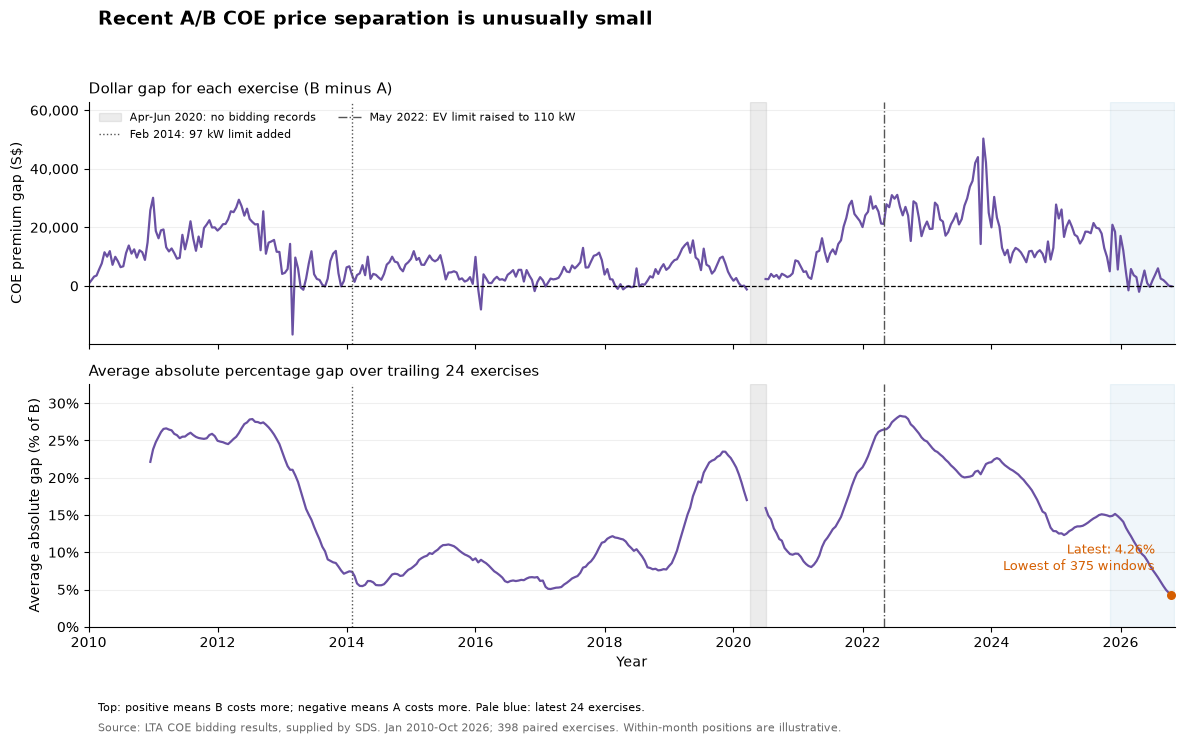

In [29]:
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)

TREND_CAT_COLORS = {"Category A": "#0072B2", "Category B": "#D55E00"}
trend_plot_months = pd.date_range(trend_history["month"].min(), trend_history["month"].max(), freq="MS")
trend_plot_index = pd.MultiIndex.from_product(
    [trend_plot_months, [1, 2]], names=["month", "bidding_no"]
)
trend_figure_data = trend_history.set_index(["month", "bidding_no"])[["gap_sgd"]].join(
    trend_rolling.set_index(["month", "bidding_no"])[["mean_abs_gap_pct_24"]]
).reindex(trend_plot_index).reset_index()
trend_month_duration = (
    trend_figure_data["month"] + pd.offsets.MonthBegin(1) - trend_figure_data["month"]
)
trend_figure_data["plot_date"] = (
    trend_figure_data["month"] + trend_month_duration * (trend_figure_data["bidding_no"] - 1) / 2
)

trend_gap_fig, trend_gap_axes = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True)
trend_panels = [
    ("gap_sgd", "Dollar gap for each exercise (B minus A)", "COE premium gap (S$)"),
    ("mean_abs_gap_pct_24", "Average absolute percentage gap over trailing 24 exercises", "Average absolute gap (% of B)"),
]
for ax, (column, title, ylabel) in zip(trend_gap_axes, trend_panels):
    ax.plot(
        trend_figure_data["plot_date"],
        trend_figure_data[column].to_numpy(dtype=float, na_value=np.nan),
        color="#6A51A3", linewidth=1.6,
    )
    ax.axvspan(pd.Timestamp("2020-04-01"), pd.Timestamp("2020-07-01"),
               color="grey", alpha=0.15, label="Apr-Jun 2020: no bidding records")
    ax.axvline(pd.Timestamp("2014-02-01"), color="#555555", linestyle=":", linewidth=1,
               label="Feb 2014: 97 kW limit added")
    ax.axvline(pd.Timestamp("2022-05-01"), color="#555555", linestyle="-.", linewidth=1,
               label="May 2022: EV limit raised to 110 kW")
    ax.axvspan(trend_latest["month"].iloc[0], trend_latest["month"].iloc[-1] + pd.offsets.MonthBegin(1),
               color="#0072B2", alpha=0.06)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(trend_figure_data["plot_date"].min().to_pydatetime(),
                trend_figure_data["plot_date"].max().to_pydatetime() + timedelta(days=20))

trend_gap_axes[0].axhline(0, color="black", linestyle="--", linewidth=0.9)
trend_gap_axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, position: f"{value:,.0f}"))
trend_gap_axes[0].set_ylim(top=trend_history["gap_sgd"].max() * 1.25)
trend_gap_axes[0].legend(loc="upper left", ncol=2, frameon=False, fontsize=8)
trend_gap_axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, position: f"{value:.0f}%"))
trend_gap_axes[1].set_ylim(0, trend_rolling["mean_abs_gap_pct_24"].max() * 1.15)
trend_gap_axes[1].scatter(
    [trend_figure_data["plot_date"].iloc[-1]], [trend_latest_rolling_gap],
    color="#D55E00", s=30, zorder=5,
)
trend_gap_axes[1].annotate(
    f"Latest: {trend_latest_rolling_gap:.2f}%\nLowest of {trend_rolling_complete} windows",
    xy=(trend_figure_data["plot_date"].iloc[-1], trend_latest_rolling_gap),
    xytext=(-12, 18), textcoords="offset points", ha="right", color="#D55E00", fontsize=9,
)
trend_year_ticks = pd.to_datetime([f"{year}-01-01" for year in range(2010, 2027, 2)])
trend_gap_axes[1].set_xticks(trend_year_ticks, [str(date.year) for date in trend_year_ticks])
trend_gap_axes[1].set_xlabel("Year")
trend_gap_fig.suptitle("Recent A/B COE price separation is unusually small",
                       x=0.09, ha="left", fontsize=14, fontweight="bold")
trend_gap_fig.text(0.09, 0.045,
                   "Top: positive means B costs more; negative means A costs more. Pale blue: latest 24 exercises.",
                   fontsize=8)
trend_gap_fig.text(0.09, 0.018,
                   "Source: LTA COE bidding results, supplied by SDS. Jan 2010-Oct 2026; 398 paired exercises. "
                   "Within-month positions are illustrative.", fontsize=8, color="dimgray")
trend_gap_fig.tight_layout(rect=(0, 0.08, 1, 0.95))
trend_gap_fig.savefig(FIGURE_DIR / "6_1_historical_coe_gap.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

**Takeaway:** The latest 24-exercise average absolute percentage gap is **4.26%, the sample minimum**, but earlier narrowing was followed by widening. The current split recently provides little COE price separation; the chart cannot establish that this will last or that vehicle values have converged.

### 6.2 Convergence came through A becoming more expensive

Compare observed average premiums in two equally sized, non-overlapping 24-exercise windows. The axis starts at zero, colours identify categories, and the percentages show changes in the averages between windows. These are nominal COE prices, not total vehicle costs or forecasts.

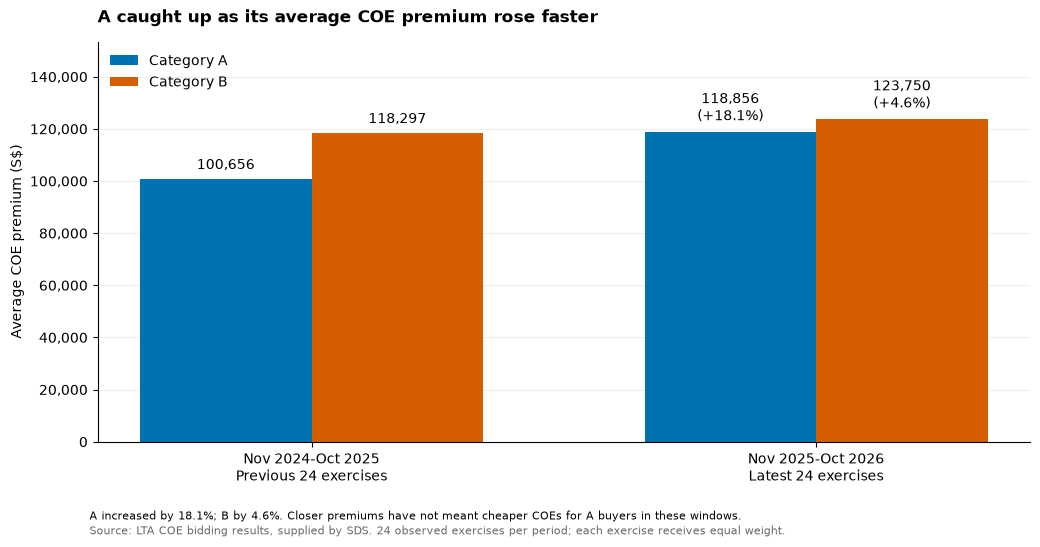

In [30]:
trend_bar_fig, trend_bar_ax = plt.subplots(figsize=(10.5, 5.5))
trend_x = np.arange(2)
trend_bar_width = 0.34
trend_mean_a = [trend_previous["premium_a"].mean(), trend_latest["premium_a"].mean()]
trend_mean_b = [trend_previous["premium_b"].mean(), trend_latest["premium_b"].mean()]
trend_bars_a = trend_bar_ax.bar(
    trend_x - trend_bar_width / 2, trend_mean_a, trend_bar_width,
    color=TREND_CAT_COLORS["Category A"], label="Category A",
)
trend_bars_b = trend_bar_ax.bar(
    trend_x + trend_bar_width / 2, trend_mean_b, trend_bar_width,
    color=TREND_CAT_COLORS["Category B"], label="Category B",
)
trend_bar_ax.bar_label(
    trend_bars_a,
    labels=[f"{trend_mean_a[0]:,.0f}", f"{trend_mean_a[1]:,.0f}\n(+{trend_a_increase_pct:.1f}%)"],
    padding=5, fontsize=10,
)
trend_bar_ax.bar_label(
    trend_bars_b,
    labels=[f"{trend_mean_b[0]:,.0f}", f"{trend_mean_b[1]:,.0f}\n(+{trend_b_increase_pct:.1f}%)"],
    padding=5, fontsize=10,
)
trend_bar_ax.set_xticks(trend_x, ["Nov 2024-Oct 2025\nPrevious 24 exercises", "Nov 2025-Oct 2026\nLatest 24 exercises"])
trend_bar_ax.set_ylabel("Average COE premium (S$)")
trend_bar_ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, position: f"{value:,.0f}"))
trend_bar_ax.set_ylim(0, max(trend_mean_a + trend_mean_b) * 1.24)
trend_bar_ax.set_title("A caught up as its average COE premium rose faster", loc="left", fontweight="bold", pad=14)
trend_bar_ax.legend(loc="upper left", frameon=False)
trend_bar_ax.grid(axis="y", alpha=0.2)
trend_bar_ax.set_axisbelow(True)
trend_bar_ax.spines[["top", "right"]].set_visible(False)
trend_bar_fig.text(0.09, 0.045,
                   "A increased by 18.1%; B by 4.6%. Closer premiums have not meant cheaper COEs for A buyers in these windows.",
                   fontsize=8)
trend_bar_fig.text(0.09, 0.018,
                   "Source: LTA COE bidding results, supplied by SDS. 24 observed exercises per period; each exercise receives equal weight.",
                   fontsize=8, color="dimgray")
trend_bar_fig.tight_layout(rect=(0, 0.08, 1, 1))
trend_bar_fig.savefig(FIGURE_DIR / "6_2_premium_convergence.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

**Takeaway:** A's average premium rose by about **S$18,199 (18.1%)**, compared with **S$5,453 (4.6%)** for B. A lost much of its COE price advantage through rising premiums. This supports reviewing buyer protection, but does not identify the cause or demonstrate that a merger would improve outcomes.

### 6.3 Pure EVs gain reported registration share

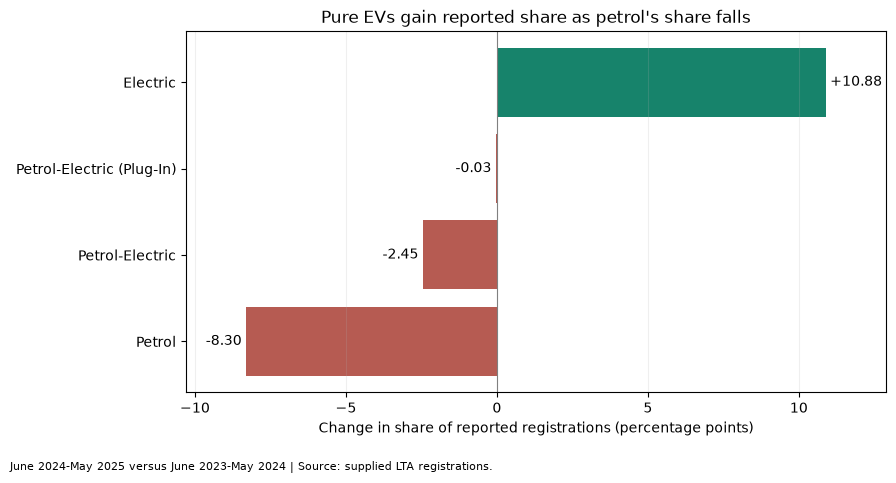

In [31]:
fuel_plot = market_fuel_mix_summary.dropna(subset=["Change (pp)"]).sort_values("Change (pp)")
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(
    fuel_plot.index, fuel_plot["Change (pp)"],
    color=["#17836b" if value >= 0 else "#b65b52" for value in fuel_plot["Change (pp)"]],
)
for position, value in enumerate(fuel_plot["Change (pp)"]):
    ax.text(value + (0.15 if value >= 0 else -0.15), position,
            f"{value:+.2f}", ha="left" if value >= 0 else "right", va="center")
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlim(fuel_plot["Change (pp)"].min() - 2, fuel_plot["Change (pp)"].max() + 2)
ax.set_xlabel("Change in share of reported registrations (percentage points)")
ax.set_title("Pure EVs gain reported share as petrol's share falls")
ax.grid(axis="x", alpha=0.2)
fig.text(0.01, 0.01, "June 2024-May 2025 versus June 2023-May 2024 | Source: supplied LTA registrations.", fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(FIGURE_DIR / "6_3_fuel_share_changes.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

**Insight:** The largest fuel-share shift is towards pure EVs; petrol-electric hybrids remain the largest reported fuel group in the latest window.

### 6.4 BYD leads the comparable make-share gains

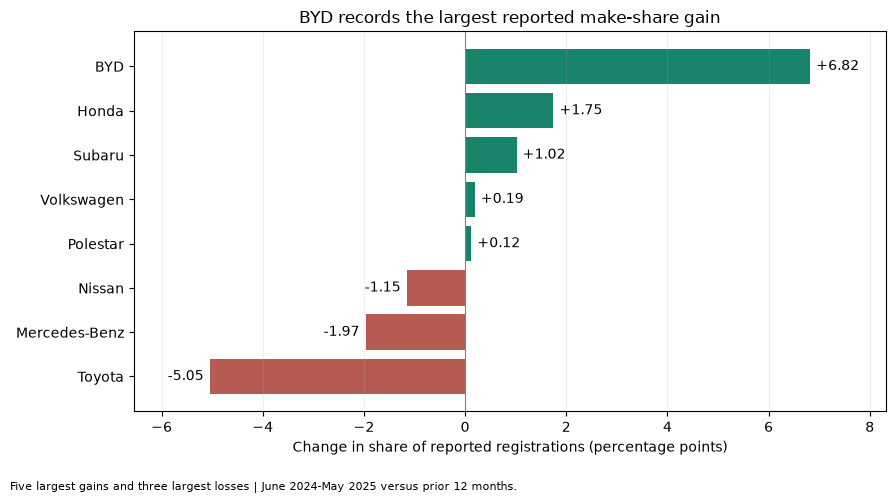

In [32]:
make_plot = market_make_mix_display.sort_values("Change (pp)")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    make_plot.index, make_plot["Change (pp)"],
    color=["#17836b" if value >= 0 else "#b65b52" for value in make_plot["Change (pp)"]],
)
for position, value in enumerate(make_plot["Change (pp)"]):
    ax.text(value + (0.12 if value >= 0 else -0.12), position,
            f"{value:+.2f}", ha="left" if value >= 0 else "right", va="center")
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlim(make_plot["Change (pp)"].min() - 1.5, make_plot["Change (pp)"].max() + 1.5)
ax.set_xlabel("Change in share of reported registrations (percentage points)")
ax.set_title("BYD records the largest reported make-share gain")
ax.grid(axis="x", alpha=0.2)
fig.text(0.01, 0.01, "Five largest gains and three largest losses | June 2024-May 2025 versus prior 12 months.", fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(FIGURE_DIR / "6_4_make_share_changes.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

**Insight:** The brand shift extends beyond a luxury/non-luxury split: BYD, Honda and Subaru lead the comparable reported-share gains while several established makes lose share.

### 6.5 Both categories face bidding pressure

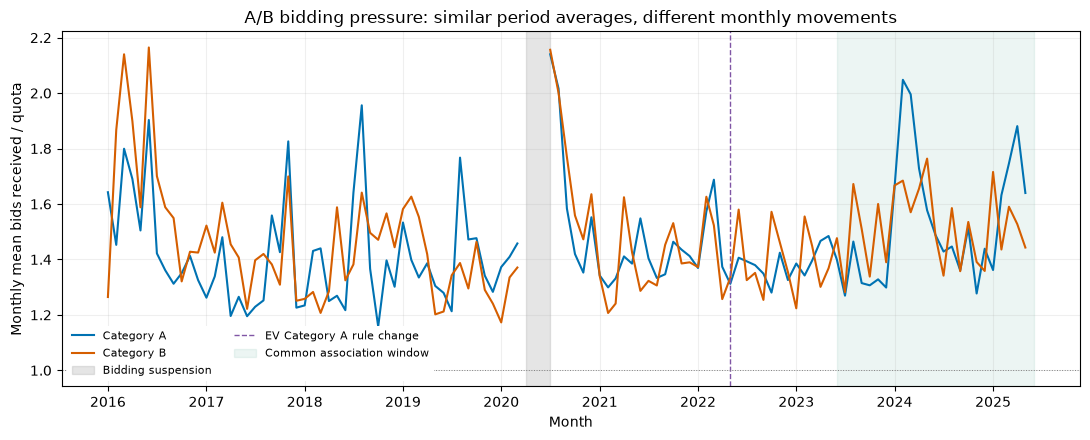

In [33]:
MARKET_CONTEXT_START, MARKET_CONTEXT_END = "2023-06-01", "2025-05-01"
fig, ax = plt.subplots(figsize=(11, 4.5))
for category, colour in [("Category A", "#0072B2"), ("Category B", "#D55E00")]:
    ax.plot(market_ab_pressure.index, market_ab_pressure[category], label=category, color=colour)
ax.axvspan(pd.Timestamp("2020-04-01"), pd.Timestamp("2020-07-01"),
           color="grey", alpha=0.2, label="Bidding suspension")
ax.axvline(pd.Timestamp("2022-05-01"), color="#8056a5", linestyle="--",
           linewidth=1, label="EV Category A rule change")
ax.axvspan(pd.Timestamp(MARKET_CONTEXT_START), pd.Timestamp("2025-06-01"),
           color="#17836b", alpha=0.08, label="Common association window")
ax.axhline(1, color="grey", linewidth=0.7, linestyle=":")
ax.set_title("A/B bidding pressure: similar period averages, different monthly movements")
ax.set_ylabel("Monthly mean bids received / quota")
ax.set_xlabel("Month")
ax.grid(alpha=0.2)
ax.legend(loc="lower left", frameon=True, facecolor="white",
          framealpha=1, edgecolor="none", fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "6_5_ab_bidding_pressure.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

**Insight:** Both categories average more bids than quota in the common window; mean monthly pressure is 1.53 for A and 1.52 for B. Their pressure series varies month to month, providing a comparison for the changing mix.

### 6.6 EV/BYD share associations are stronger for A

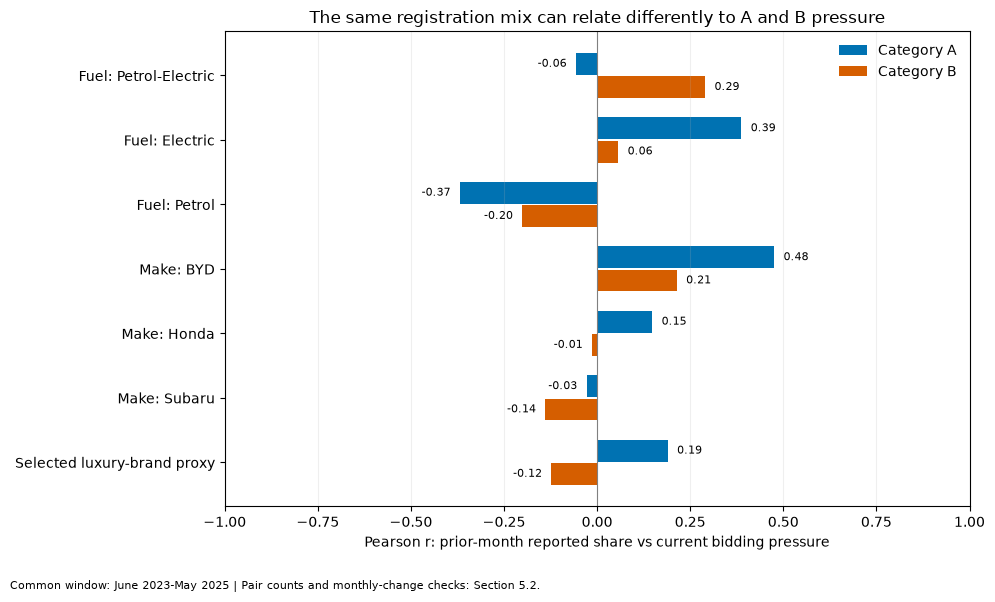

In [34]:
market_lag_comparison = (
    market_mix_pressure_associations.pivot(
        index="Registration share", columns="Category", values="Prior-month r"
    ).reindex(list(market_association_series))
)
positions = np.arange(len(market_lag_comparison))
fig, ax = plt.subplots(figsize=(10, 6))
for offset, category, colour in [
    (-0.18, "Category A", "#0072B2"), (0.18, "Category B", "#D55E00")
]:
    values = market_lag_comparison[category]
    ax.barh(positions + offset, values, height=0.34, color=colour, label=category)
    for position, value in zip(positions + offset, values):
        if pd.notna(value):
            ax.text(value + (0.025 if value >= 0 else -0.025), position,
                    f"{value:.2f}", va="center", ha="left" if value >= 0 else "right", fontsize=8)
ax.set_yticks(positions, market_lag_comparison.index)
ax.invert_yaxis()
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlim(-1, 1)
ax.set_xlabel("Pearson r: prior-month reported share vs current bidding pressure")
ax.set_title("The same registration mix can relate differently to A and B pressure")
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.2)
fig.text(0.01, 0.01, "Common window: June 2023-May 2025 | Pair counts and monthly-change checks: Section 5.2.", fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(FIGURE_DIR / "6_6_mix_ab_pressure_associations.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

**Insight:** EV and BYD reported shares have stronger prior-month associations with A pressure (r = 0.39 and 0.48) than with B (r = 0.06 and 0.21). Their monthly-change associations with A are near zero, so this is primarily evidence of a pattern in levels over the selected period.

### 6.7 Similar COE premiums coexist with different listed vehicle values

Compare all 237 listed entries in the September 2026 snapshot. Dots represent entries, boxes show the middle 50%, and black lines mark category medians. Whiskers extend to the most distant observations within 1.5 interquartile ranges of the box; all entries, including those beyond the whiskers, are plotted. Horizontal jitter separates overlapping dots and has no numerical meaning. Each listed entry receives equal weight.

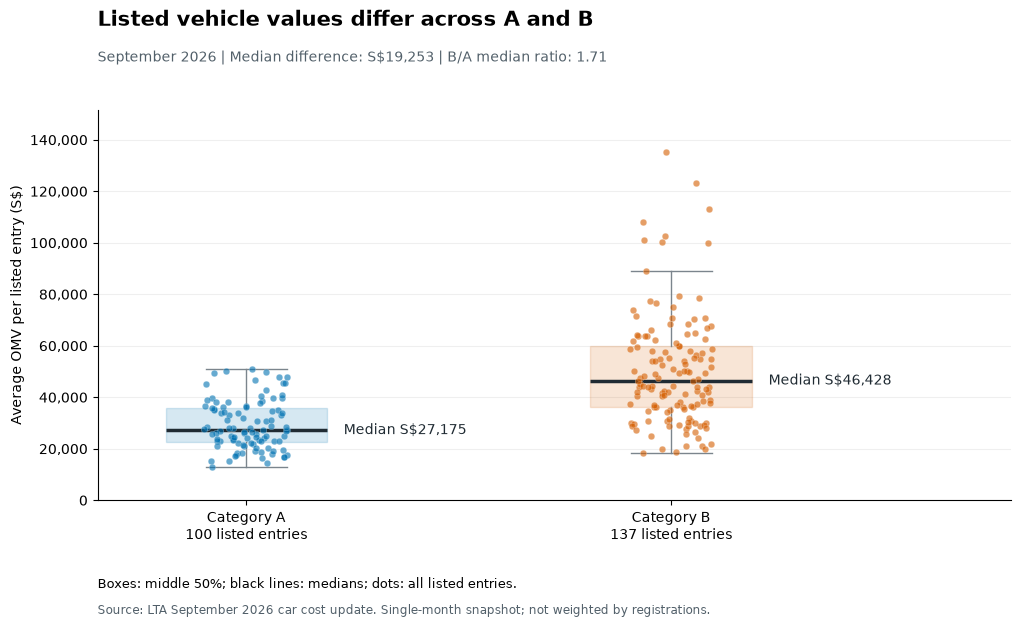

In [35]:
omv_distribution_fig, omv_distribution_ax = plt.subplots(figsize=(10.5, 6.5))
omv_distribution_fig.subplots_adjust(left=0.10, right=0.97, top=0.81, bottom=0.21)
omv_plot_values = [
    ab_models.loc[ab_models["COE Category"].eq(category), omv_col].to_numpy(dtype=float)
    for category in ["A", "B"]
]
omv_boxes = omv_distribution_ax.boxplot(
    omv_plot_values, positions=[1, 2], widths=0.38, patch_artist=True,
    showfliers=False, whis=1.5,
    medianprops={"color": "#202B33", "linewidth": 2.5},
    whiskerprops={"color": "#7B858D", "linewidth": 1},
    capprops={"color": "#7B858D", "linewidth": 1},
)
omv_jitter_rng = np.random.default_rng(SEED + 603)
for position, values, category, box in zip(
    [1, 2], omv_plot_values, ["A", "B"], omv_boxes["boxes"]
):
    color = TREND_CAT_COLORS[f"Category {category}"]
    box.set_facecolor(color)
    box.set_alpha(0.16)
    box.set_edgecolor(color)
    jitter = omv_jitter_rng.uniform(-0.10, 0.10, len(values))
    omv_distribution_ax.scatter(position + jitter, values, s=23, color=color,
                                alpha=0.60, edgecolors="white", linewidths=0.25, zorder=3)
    median = float(np.median(values))
    omv_distribution_ax.annotate(
        f"Median S${median:,.0f}", xy=(position + 0.19, median),
        xytext=(12, 0), textcoords="offset points", va="center", fontsize=10,
        color="#202B33", bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.88, "pad": 2},
    )
omv_distribution_ax.set_xticks(
    [1, 2], [f"Category A\n{len(omv_plot_values[0])} listed entries",
             f"Category B\n{len(omv_plot_values[1])} listed entries"]
)
omv_distribution_ax.set_xlim(0.65, 2.80)
omv_distribution_ax.set_ylim(0, max(values.max() for values in omv_plot_values) * 1.12)
omv_distribution_ax.set_ylabel("Average OMV per listed entry (S$)")
omv_distribution_ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
omv_distribution_ax.grid(axis="y", alpha=0.2)
omv_distribution_ax.set_axisbelow(True)
omv_distribution_ax.spines[["top", "right"]].set_visible(False)
omv_distribution_fig.text(0.10, 0.94, "Listed vehicle values differ across A and B",
                          fontsize=15, fontweight="bold")
omv_distribution_fig.text(0.10, 0.885,
                          f"September 2026 | Median difference: S${omv_median_difference:,.0f} | B/A median ratio: {omv_median_ratio:.2f}",
                          fontsize=10, color="#52606A")
omv_distribution_fig.text(0.10, 0.075, "Boxes: middle 50%; black lines: medians; dots: all listed entries.", fontsize=9)
omv_distribution_fig.text(0.10, 0.035,
                          "Source: LTA September 2026 car cost update. Single-month snapshot; not weighted by registrations.",
                          fontsize=8.5, color="#52606A")
omv_distribution_fig.savefig(FIGURE_DIR / "6_7_listed_omv_by_category.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

**Takeaway:** B's median listed OMV is **S$46,428**, versus **S$27,175** for A. Typical listed values differ even when recent COE premiums are close. The full value ranges overlap, and this unweighted snapshot does not establish the distribution of cars actually purchased across the market.

### 6.8 Conditional forecasts allow for renewed price separation

Show historical A/B premiums, their exercise-specific quota-weighted average,
and the selected 24-round forecasts. Future weighted prices hold the latest
exercise's quotas fixed. The second chart adds the discrete adjustment ranges.
Both are conditional scenarios; the weighted average is not an estimated
merged-auction clearing price. Category B's rounds 13-24 exceed its evaluated horizon.

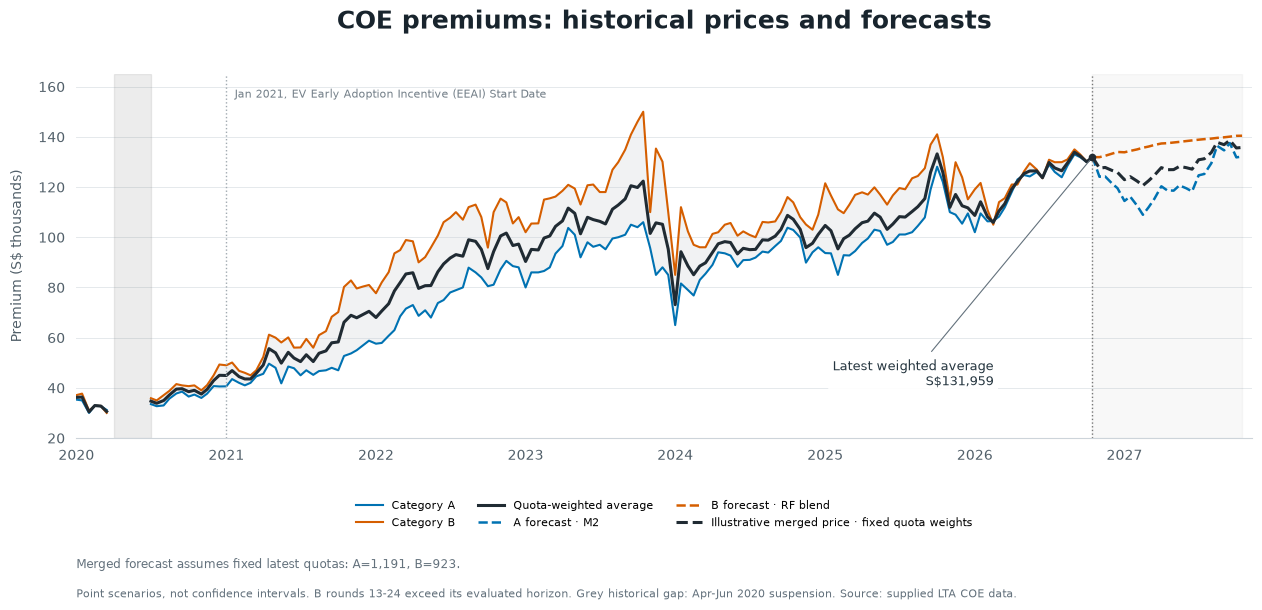

In [36]:
coe_merged_plot = ab_trends.copy()
coe_merged_plot['weighted_premium'] = (
    coe_merged_plot['premium_a'] * coe_merged_plot['quota_a']
    + coe_merged_plot['premium_b'] * coe_merged_plot['quota_b']
) / (coe_merged_plot['quota_a'] + coe_merged_plot['quota_b'])

# Historical prices and forecasts.
chart_data = coe_merged_plot.loc[
    coe_merged_plot['month'] >= pd.Timestamp('2020-01-01'),
    ['month', 'bidding_no', 'premium_a', 'premium_b', 'weighted_premium'],
].sort_values(['month', 'bidding_no']).copy()
if chart_data.empty:
    raise ValueError('No observations match the selected date range.')

# Add empty plotting positions for absent months; do not connect across suspension.
chart_index = pd.MultiIndex.from_product(
    [pd.date_range(chart_data["month"].min(), chart_data["month"].max(), freq="MS"), [1, 2]],
    names=["month", "bidding_no"],
)
chart_data = chart_data.set_index(["month", "bidding_no"]).reindex(chart_index).reset_index()
assert chart_data.loc[chart_data["month"].between("2020-04-01", "2020-06-01"),
                      ["premium_a", "premium_b", "weighted_premium"]].isna().all().all()
# Display spacing only: R1 at month start, R2 14 days later (not actual auction dates).
dates = chart_data['month'] + pd.to_timedelta((chart_data['bidding_no'].astype(int)-1)*14, unit='D')
a = chart_data['premium_a'].to_numpy(dtype=float) / 1000
b = chart_data['premium_b'].to_numpy(dtype=float) / 1000
weighted = chart_data['weighted_premium'].to_numpy(dtype=float) / 1000

future_chart = combined_forecasts.loc[
    combined_forecasts['date'].gt(chart_data['month'].iloc[-1])
].sort_values(['date', 'bidding_no']).copy()
assert not future_chart.empty
future_chart['date'] = future_chart['date'] + pd.to_timedelta((future_chart['bidding_no'].astype(int)-1)*14, unit='D')
plot_end = future_chart['date'].max()
# Future quotas are unknown: hold the latest observed exercise quotas fixed.
latest_weights = coe_merged_plot.sort_values(['month', 'bidding_no']).iloc[-1]
forecast_quota_a = float(latest_weights['quota_a'])
forecast_quota_b = float(latest_weights['quota_b'])
if forecast_quota_a <= 0 or forecast_quota_b <= 0:
    raise ValueError('Positive A/B quotas are required for the merged-price proxy.')
future_chart = future_chart.copy()
future_chart['weighted_merge_forecast'] = (
    future_chart['category_a_forecast'] * forecast_quota_a
    + future_chart['category_b_forecast'] * forecast_quota_b
) / (forecast_quota_a + forecast_quota_b)

with plt.rc_context({'font.size': 10, 'axes.titlesize': 12,
                     'axes.labelsize': 10, 'figure.facecolor': 'white',
                     'axes.facecolor': 'white', 'font.family': 'sans-serif'}):
    fig, ax = plt.subplots(figsize=(14, 6.5))
    fig.subplots_adjust(left=0.08, right=0.92, top=0.83, bottom=0.27)
    fig.text(0.5, 0.90, 'COE premiums: historical prices and forecasts',
             fontsize=18, fontweight='bold', color='#18242D', ha='center')

    ax.fill_between(dates, np.minimum(a, b), np.maximum(a, b),
                    color='#C8CDD3', alpha=0.25, linewidth=0)
    ax.plot(dates, a, color='#0072B2', linewidth=1.5, label='Category A')
    ax.plot(dates, b, color='#D55E00', linewidth=1.5, label='Category B')
    ax.plot(dates, weighted, color='#202B33', linewidth=2.2,
            label='Quota-weighted average')
    for column, latest, color, label in [
        ('category_a_forecast', a[-1], '#0072B2', 'A forecast · M2'),
        ('category_b_forecast', b[-1], '#D55E00', 'B forecast · RF blend'),
    ]:
        forecast_dates = pd.concat([pd.Series([dates.iloc[-1]]), future_chart['date']], ignore_index=True)
        forecast_values = np.r_[latest, future_chart[column].to_numpy(dtype=float) / 1000]
        ax.plot(forecast_dates, forecast_values, color=color,
                linestyle='--', linewidth=1.8, label=label)
    ax.plot(
        pd.concat([pd.Series([dates.iloc[-1]]), future_chart['date']], ignore_index=True),
        np.r_[weighted[-1], future_chart['weighted_merge_forecast'].to_numpy() / 1000],
        color='#202B33', linestyle='--', linewidth=2.2,
        label='Illustrative merged price · fixed quota weights',
    )
    ax.axvspan(pd.Timestamp('2020-04-01'), pd.Timestamp('2020-07-01'), color='grey', alpha=0.15)
    ax.axvspan(dates.iloc[-1], plot_end, color='#777777', alpha=0.05)
    ax.axvline(dates.iloc[-1], color='#777777', linestyle=':', linewidth=1)
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, 0.115),
               ncol=3, frameon=False, fontsize=8, handlelength=2.4, columnspacing=2)
    ax.annotate(f'Latest weighted average\nS${weighted[-1] * 1000:,.0f}',
                xy=(dates.iloc[-1], weighted[-1]), xytext=(0.78, 0.22),
                textcoords='axes fraction', fontsize=9, color='#263640',
                va='top', ha='right', annotation_clip=True,
                bbox=dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='none', alpha=0.95),
                arrowprops=dict(arrowstyle='-', color='#63717C', linewidth=0.8))
    ax.scatter(dates.iloc[-1], weighted[-1], color='#202B33', s=20, zorder=5)

    policy_date = pd.Timestamp('2021-01-01')
    lower = max(0, np.floor(min(np.nanmin(a), np.nanmin(b), np.nanmin(weighted)) / 20) * 20)
    upper = np.ceil(max(np.nanmax(a), np.nanmax(b), np.nanmax(weighted),
        future_chart[['category_a_forecast', 'category_b_forecast']].to_numpy().max() / 1000) / 20) * 20
    for ax in [ax]:
        ax.set_ylim(lower, upper + 5)
        ax.set_xlim(dates.iloc[0].to_pydatetime(), plot_end.to_pydatetime() + timedelta(days=25))
        ax.yaxis.set_major_locator(MultipleLocator(20))
        ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
        ax.set_ylabel('Premium (S$ thousands)', labelpad=10, color='#52606A')
        ax.grid(axis='y', color='#E5E9EC', linewidth=0.7)
        ax.grid(axis='x', visible=False)
        ax.set_axisbelow(True)
        ax.spines[['top', 'right', 'left']].set_visible(False)
        ax.spines['bottom'].set_color('#CDD4DA')
        ax.tick_params(axis='both', length=0, labelcolor='#52606A', pad=8)
        ax.axvline(policy_date, color='#A0A9B0', linestyle=':', linewidth=1)
    ax.annotate('Jan 2021, EV Early Adoption Incentive (EEAI) Start Date',
                     xy=(policy_date, 0.96), xycoords=('data', 'axes fraction'),
                     xytext=(6, 0), textcoords='offset points',
                     fontsize=8, color='#737F88', va='top')
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    fig.text(0.08, 0.07,
             f'Merged forecast assumes fixed latest quotas: A={forecast_quota_a:,.0f}, B={forecast_quota_b:,.0f}.',
             fontsize=8.5, color='#63717C')

    fig.text(0.08, 0.025,
             'Point scenarios, not confidence intervals. B rounds 13-24 exceed its evaluated horizon. '
             'Grey historical gap: Apr-Jun 2020 suspension. Source: supplied LTA COE data.',
             fontsize=8, color='#63717C')
    fig.savefig(FIGURE_DIR / '6_8a_historical_conditional_premiums.png',
                dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()

**Takeaway:** For April 2027, exercise 2, the models project approximately
**S$118,715 for A** and **S$137,471 for B**, a gap of about **S$18,756**.
The fixed-quota weighted scenario lies between them. These are conditional
projections; the combined gap has not been validated as a separate forecast target.

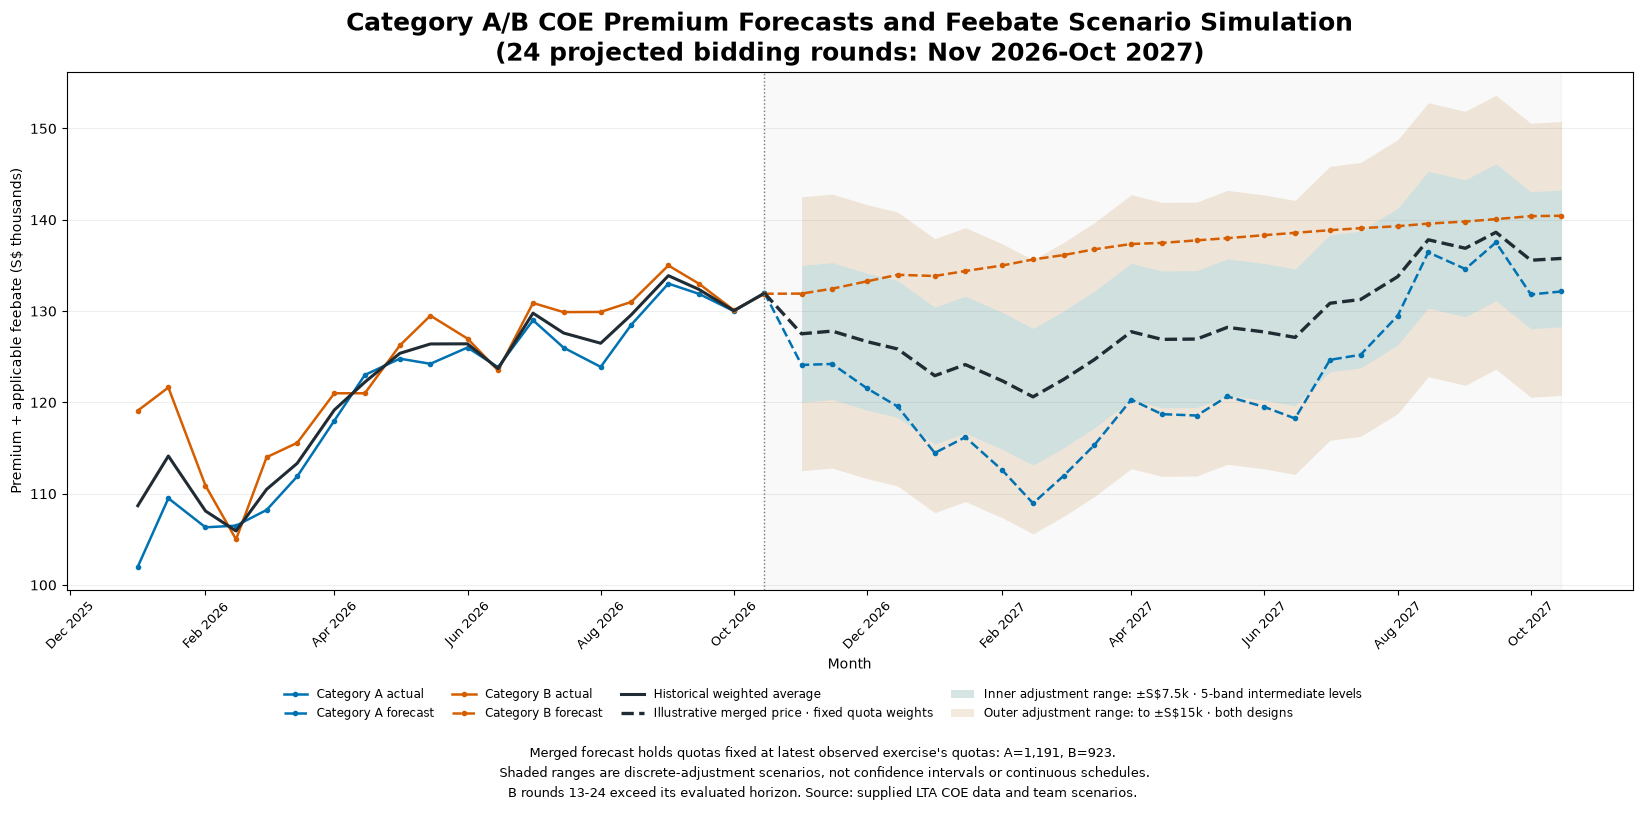

In [37]:
band_history = coe_merged_plot.loc[
    coe_merged_plot['month'].ge(pd.Timestamp('2026-01-01'))
].sort_values(['month', 'bidding_no']).copy()
band_history['month'] = band_history['month'] + pd.to_timedelta((band_history['bidding_no'].astype(int)-1)*14, unit='D')
assert not band_history.empty and not future_chart.empty
band_dates = pd.concat([pd.Series([band_history['month'].iloc[-1]]),
                        future_chart['date']], ignore_index=True)
merged_values = np.r_[band_history['weighted_premium'].iloc[-1],
                      future_chart['weighted_merge_forecast'].to_numpy()] / 1000
fig, ax = plt.subplots(figsize=(18, 8.5))
for column, future_column, color, name in [
    ('premium_a', 'category_a_forecast', '#0072B2', 'Category A'),
    ('premium_b', 'category_b_forecast', '#D55E00', 'Category B'),
]:
    ax.plot(band_history['month'], band_history[column] / 1000,
            color=color, linewidth=1.8, marker='o', markersize=3, label=f'{name} actual')
    ax.plot(band_dates, np.r_[band_history[column].iloc[-1],
                            future_chart[future_column].to_numpy()] / 1000,
            color=color, linewidth=1.8, linestyle='--', marker='o', markersize=3, label=f'{name} forecast')
ax.plot(band_history['month'], band_history['weighted_premium'] / 1000,
        color='#202B33', linewidth=2.2, label='Historical weighted average')
ax.plot(band_dates, merged_values, color='#202B33', linewidth=2.4,
        linestyle='--', label='Illustrative merged price · fixed quota weights')
# Shading illustrates the adjustment ranges, not forecast uncertainty.
merged_k = future_chart['weighted_merge_forecast'].to_numpy(dtype=float) / 1000
ax.fill_between(future_chart['date'], merged_k - 7.5, merged_k + 7.5,
                color='#428A86', alpha=0.22, linewidth=0,
                label='Inner adjustment range: ±S$7.5k · 5-band intermediate levels')
ax.fill_between(future_chart['date'], merged_k - 15, merged_k - 7.5,
                color='#C78A43', alpha=0.18, linewidth=0,
                label='Outer adjustment range: to ±S$15k · both designs')
ax.fill_between(future_chart['date'], merged_k + 7.5, merged_k + 15,
                color='#C78A43', alpha=0.18, linewidth=0)
ax.axvline(band_history['month'].iloc[-1], color='#777777', linestyle=':', linewidth=1)
ax.axvspan(band_history['month'].iloc[-1], future_chart['date'].max(),
           color='#777777', alpha=0.045)
ax.set_title('Category A/B COE Premium Forecasts and Feebate Scenario Simulation\n(24 projected bidding rounds: Nov 2026-Oct 2027)',
       fontsize = 18,
       fontweight = 'bold',
       pad = 8)
ax.set(xlabel='Month', ylabel='Premium + applicable feebate (S$ thousands)')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.tick_params(axis='x', rotation=45, labelsize=9)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, 0.085),
           ncol=4, frameon=False, fontsize=8.5, columnspacing=1.5, labelspacing=0.5)
fig.text(0.5, 0.035,
         f'Merged forecast holds quotas fixed at latest observed exercise\'s quotas: A={forecast_quota_a:,.0f}, B={forecast_quota_b:,.0f}.\n '
         'Shaded ranges are discrete-adjustment scenarios, not confidence intervals or continuous schedules.\n'         'B rounds 13-24 exceed its evaluated horizon. Source: supplied LTA COE data and team scenarios.',
         ha='center', va='center', fontsize=9, linespacing=1.6)
fig.subplots_adjust(left=0.08, right=0.95, top=0.86, bottom=0.25) 

fig.savefig(FIGURE_DIR / '6_8b_forecast_feebate_ranges.png',
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

**Takeaway:** A fixed rebate offsets the assumed merged premium by its amount.
It protects a buyer relative to A only while the merged price minus that rebate
does not exceed the same-period A reference. The shaded ranges illustrate
adjustments, rather than prediction uncertainty.

### 6.9 Rebates protect buyers only below a break-even merged premium

For each fixed adjustment, plot the cost change relative to the latest A or B premium as the assumed merged premium varies. Negative values indicate savings; dots on the zero line mark break-even premiums. The panels are alternative reference cases, not observed assignments of OMV groups to categories. The vertical lines show the quota-weighted base assumption and the base plus S$15,000 stress case.

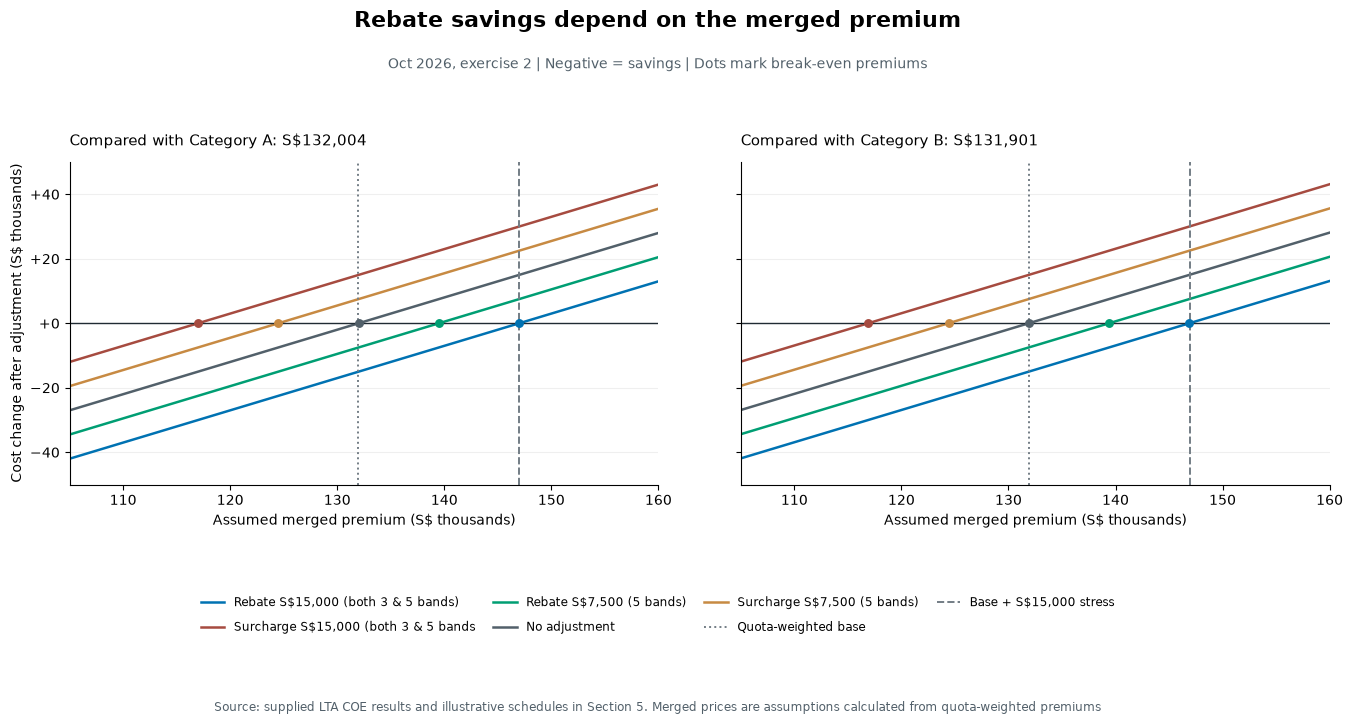

In [38]:
merger_plot_lower = np.floor((min(merger_reference_prices.values()) - 25000) / 5000) * 5000
merger_plot_upper = np.ceil((max(merger_reference_prices.values()) + 25000) / 5000) * 5000
merger_plot_grid = np.linspace(max(0, merger_plot_lower), merger_plot_upper, 221)
merger_line_styles = [
    (-15000, "#0072B2", "Rebate S$15,000 (both 3 & 5 bands)"),
    (15000, '#A64B40', 'Surcharge S$15,000 (both 3 & 5 bands'),
    (-7500, "#009E73", "Rebate S$7,500 (5 bands)"),
    (0, "#52606A", "No adjustment"),
    (7500, "#C78A43", "Surcharge S$7,500 (5 bands)"),
]
merger_break_even_fig, merger_break_even_axes = plt.subplots(1, 2, figsize=(14, 7.5), sharex=True, sharey=True)
merger_break_even_fig.subplots_adjust(left=0.08, right=0.98, top=0.76, bottom=0.33, wspace=0.14)
merger_plot_rows = []
for ax, (category, existing_price) in zip(merger_break_even_axes, merger_reference_prices.items()):
    for adjustment, color, label in merger_line_styles:
        changes = merger_plot_grid + adjustment - existing_price
        ax.plot(merger_plot_grid / 1000, changes / 1000, color=color, linewidth=1.8, label=label)
        threshold = float(merger_break_even_thresholds.loc[
            merger_break_even_thresholds["reference"].eq(category)
            & merger_break_even_thresholds["adjustment_sgd"].eq(adjustment),
            "break_even_merged_premium",
        ].iloc[0])
        ax.scatter(threshold / 1000, 0, color=color, s=29, zorder=5)
        merger_plot_rows.extend({"reference": category, "adjustment_sgd": adjustment,
                                 "assumed_merged_premium": premium, "cost_change_sgd": change}
                                for premium, change in zip(merger_plot_grid, changes))
    ax.axhline(0, color="#202B33", linewidth=1)
    ax.axvline(merger_base_premium / 1000, color="#737D85", linestyle=":", linewidth=1.4,
               label="Quota-weighted base")
    ax.axvline((merger_base_premium + 15000) / 1000, color="#737D85", linestyle="--", linewidth=1.4,
               label="Base + S$15,000 stress")
    ax.set_title(f"Compared with {category}: S${existing_price:,.0f}", loc="left", fontsize=11, pad=12)
    ax.set_xlabel("Assumed merged premium (S$ thousands)")
    ax.xaxis.set_major_locator(MultipleLocator(10))
    ax.yaxis.set_major_locator(MultipleLocator(20))
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:+.0f}"))
    ax.set_xlim(merger_plot_grid[0] / 1000, merger_plot_grid[-1] / 1000)
    ax.set_ylim(-50, 50)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
merger_break_even_axes[0].set_ylabel("Cost change after adjustment (S$ thousands)")
merger_plot_data = pd.DataFrame(merger_plot_rows)
merger_break_even_fig.text(0.5, 0.94, "Rebate savings depend on the merged premium", fontsize=16, fontweight="bold", ha="center")
merger_break_even_fig.text(0.5, 0.885,
                          f"{merger_latest['month']:%b %Y}, exercise {int(merger_latest['bidding_no'])} | Negative = savings | Dots mark break-even premiums",
                          fontsize=10, color="#52606A", ha="center")
merger_legend_handles, merger_legend_labels = merger_break_even_axes[0].get_legend_handles_labels()
merger_break_even_fig.legend(merger_legend_handles, merger_legend_labels, loc="upper center",
                             bbox_to_anchor=(0.5, 0.20), ncol=4, frameon=False, fontsize=8.5,
                             columnspacing=1.5, labelspacing=1.0, borderaxespad=0.8)
merger_break_even_fig.text(0.5, 0.028, "Source: supplied LTA COE results and illustrative schedules in Section 5. Merged prices are assumptions calculated from quota-weighted premiums",
                          fontsize=8.5, color="#52606A", ha="center")
merger_break_even_fig.savefig(FIGURE_DIR / "6_9_feebate_break_even.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

**Takeaway:** Relative to the latest A premium, a **S$15,000 rebate** breaks even at a merged premium of **S$147,004**; a **S$7,500 rebate** breaks even at **S$139,504**. Above these thresholds, the buyer pays more than the existing A reference price. Smaller five-band adjustments reduce some surcharges but also leave some buyers with smaller rebates, so protection depends on the resulting merged premium.

### 6.10 OMV distributions and illustrative band cutoffs

Compare Category A, Category B and their pooled OMVs in the September 2026 listed-vehicle table. Horizontal lines mark the provisional three- and five-band percentile cutoffs calculated from the pooled sample. Each listed entry counts equally; these are not sales-weighted or official dollar thresholds.

This analysis uses the September 2026 car-cost dataset; each row represents a listed vehicle model/variant, not sales volume.


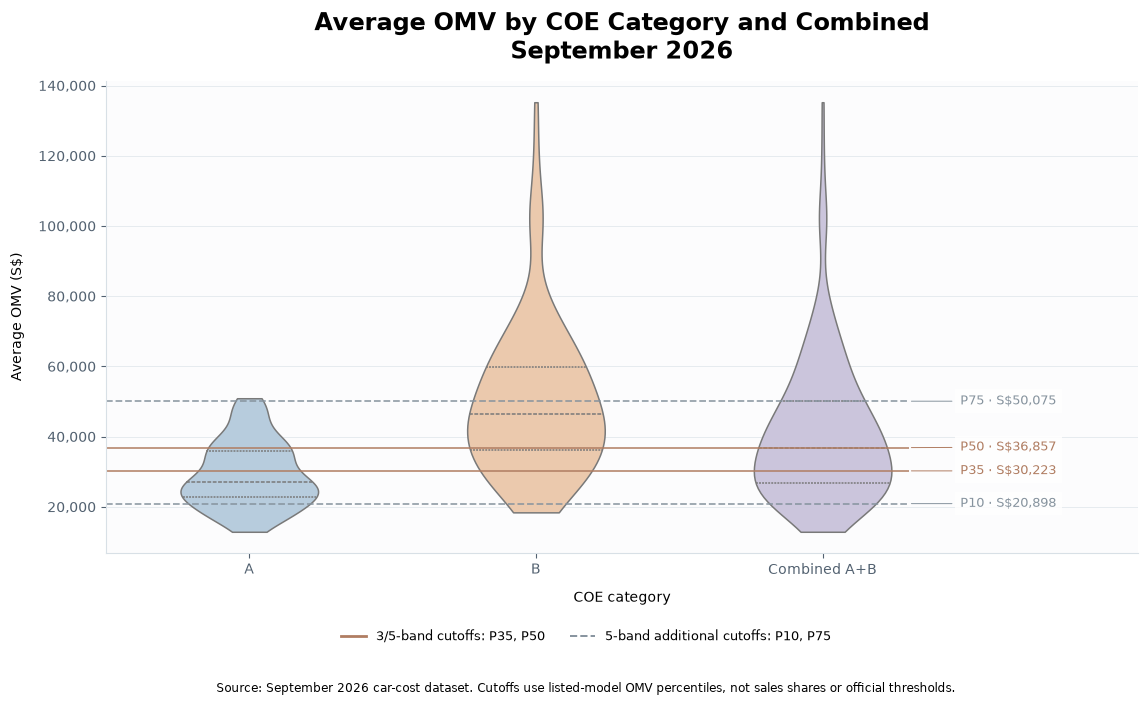

In [39]:
sep = ab_models.copy()  # Reuse the validated September snapshot from Section 3.
print('This analysis uses the September 2026 car-cost dataset; each row represents a listed vehicle model/variant, not sales volume.')

# Distribution across listed model/variant rows, not registration-weighted sales.
omv_distribution = sep[['Average OMV (S$)', 'COE Category']].copy()
assert omv_distribution.notna().all().all()
# Pool every listed A/B row once for the combined distribution.
omv_distribution = omv_distribution.loc[omv_distribution['COE Category'].isin(['A', 'B'])]
omv_plot_data = pd.concat([
    omv_distribution,
    omv_distribution.assign(**{'COE Category': 'Combined A+B'}),
], ignore_index=True)
fig, ax = plt.subplots(figsize=(12, 7.5))
palette = {'A': '#B7CCDD', 'B': '#EBC9AD', 'Combined A+B': '#CBC5DC'}
fig.patch.set_facecolor('white')
ax.set_facecolor('#FCFCFD')
sns.violinplot(
    data=omv_plot_data, x='COE Category', y='Average OMV (S$)',
    hue='COE Category', palette=palette, order=['A', 'B', 'Combined A+B'],
    inner='quart', cut=0, density_norm='width', width=0.48,
    saturation=1, linewidth=1.1, legend=False, ax=ax,
)
# Provisional band cutoffs from the pooled listed-model OMV distribution.
# Three bands: <=35th, 35th–50th, >50th percentile.
# Five bands add the 10th and 75th percentile cutoffs.
omv_band_cutoffs = omv_distribution['Average OMV (S$)'].quantile([0.10, 0.35, 0.50, 0.75])
label_gap = 0.055 * (omv_distribution['Average OMV (S$)'].max() - omv_distribution['Average OMV (S$)'].min())
previous_label_y = -np.inf
for percentile, amount in omv_band_cutoffs.items():
    shared_cutoff = percentile in [0.35, 0.50]
    color = '#B07D62' if shared_cutoff else '#86939E'
    ax.hlines(amount, -0.5, 2.30, color=color,
              linestyle='-' if shared_cutoff else '--', linewidth=1.3, alpha=0.85, zorder=2)
    label_y = max(float(amount), previous_label_y + label_gap)
    previous_label_y = label_y
    ax.annotate(f'P{percentile*100:.0f} · S${amount:,.0f}',
                xy=(2.30, amount), xytext=(2.48, label_y), textcoords='data',
                va='center', ha='left', fontsize=9, color=color,
                arrowprops=dict(arrowstyle='-', color=color, linewidth=0.7),
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.85))
handles, labels = ax.get_legend_handles_labels()
handles.extend([
    Line2D([0], [0], color='#B07D62', linewidth=2, label='3/5-band cutoffs: P35, P50'),
    Line2D([0], [0], color='#86939E', linewidth=1.4, linestyle='--', label='5-band additional cutoffs: P10, P75'),
])
ax.set_xlim(-0.5, 3.1)
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.075),
           frameon=False, ncol=2, fontsize=9, columnspacing=2)
ax.set(title='Average OMV by COE Category and Combined\nSeptember 2026',
       xlabel='COE category', ylabel='Average OMV (S$)')
ax.set_title(ax.get_title(), fontsize=17, fontweight='bold', pad=16)
ax.set_xlabel('COE category', labelpad=10)
ax.set_ylabel('Average OMV (S$)', labelpad=10)
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.grid(axis='y', color='#E6EBEF', linewidth=0.7)
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#D8E0E6')
ax.tick_params(colors='#526170')
ax.set_axisbelow(True)
fig.text(0.5, 0.025, 'Source: September 2026 car-cost dataset. Cutoffs use listed-model OMV percentiles, not sales shares or official thresholds.',
         ha='center', fontsize=8.5)
fig.subplots_adjust(left=0.10, right=0.96, top=0.84, bottom=0.21)

fig.savefig(FIGURE_DIR / '6_10_listed_omv_illustrative_cutoffs.png',
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

**Interpretation:** Category B generally contains higher-OMV vehicles, but its OMVs overlap with A. OMV-based adjustments therefore need not match existing COE categories. The pooled cutoffs describe this month's listed entries, not percentages of buyers.

### 6.11 Matched lower-OMV buyers: savings after merger

Compare hypothetical A/B cars with the same **S$27,500 OMV**, placing them in the sample's **10th–35th percentile band**. Hold non-COE basic costs equal and unchanged. Use September 2026 R1 COE premiums and their quota-weighted merged-price proxy. The provisional rebate is S$15,000 under three bands and S$7,500 under five bands.

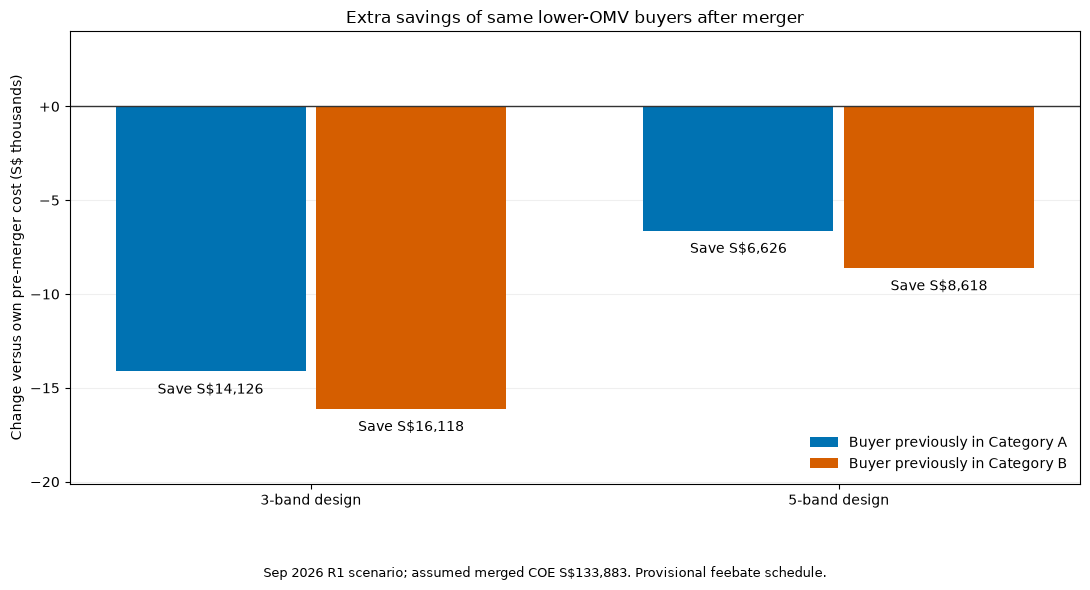

In [40]:
# Editable assumptions for two matched hypothetical cars.
SAME_OMV = 27_500
COMMON_NON_COE_BASIC_COST = 80_000  # Includes OMV, not an additional charge on top of OMV.
assert COMMON_NON_COE_BASIC_COST >= SAME_OMV

sample_omv = sep[omv_col].astype(float)
matched_percentile = 100 * ((sample_omv < SAME_OMV).sum()
    + 0.5*(sample_omv == SAME_OMV).sum()) / len(sample_omv)

def matched_feebate(percentile, design):
    if percentile <= 10: return -15000
    if percentile <= 35: return -15000 if design == '3-band' else -7500
    if percentile <= 50: return 0
    if percentile <= 75: return 15000 if design == '3-band' else 7500
    return 15000


matched_round = coe.loc[
    coe['month'].eq(OMV_SNAPSHOT_MONTH)
    & coe['bidding_no'].eq(1)
    & coe['vehicle_class'].isin(['Category A', 'Category B'])
].set_index('vehicle_class')
assert len(matched_round) == 2
matched_merged_coe = float((matched_round['premium'] * matched_round['quota']).sum()
                          / matched_round['quota'].sum())

assert 10 < matched_percentile <= 35, "The lower-OMV illustration must remain in its stated band."
matched_records = []
for category in ['Category A', 'Category B']:
    old_coe = float(matched_round.loc[category, 'premium'])
    for scenario, premium, fee in [
        ('Before merger', old_coe, 0),
        ('After: 3 bands', matched_merged_coe, matched_feebate(matched_percentile, '3-band')),
        ('After: 5 bands', matched_merged_coe, matched_feebate(matched_percentile, '5-band')),
    ]:
        matched_records.append({'Existing category': category, 'Scenario': scenario,
            'OMV': SAME_OMV, 'Non-COE basic cost': COMMON_NON_COE_BASIC_COST,
            'COE': premium, 'Feebate': fee,
            'Simulated basic cost': COMMON_NON_COE_BASIC_COST + premium + fee,
            'Change versus before': premium + fee - old_coe})
matched_buyer_costs = pd.DataFrame(matched_records)


# Same matched-buyer scenario: savings relative to each buyer's original cost.
spending_changes = matched_buyer_costs.loc[matched_buyer_costs['Scenario'].ne('Before merger')].copy()
fig, ax = plt.subplots(figsize=(11, 6))
for offset, category, color in [(-0.19, 'Category A', '#0072B2'), (0.19, 'Category B', '#D55E00')]:
    rows = spending_changes.loc[spending_changes['Existing category'].eq(category)].set_index('Scenario').loc[['After: 3 bands', 'After: 5 bands']]
    bars = ax.bar(np.arange(2)+offset, rows['Change versus before']/1000, width=0.36,
                  color=color, label=f'Buyer previously in {category}')
    for bar, amount in zip(bars, rows['Change versus before']):
        label = f'Save S${abs(amount):,.0f}' if amount < 0 else f'Pay S${amount:,.0f} more'
        ax.annotate(label, (bar.get_x()+bar.get_width()/2, bar.get_height()),
                    xytext=(0, -8 if amount < 0 else 8), textcoords='offset points',
                    ha='center', va='top' if amount < 0 else 'bottom', fontsize=10)
ax.axhline(0, color='#333333', linewidth=1)
ax.set_xticks(np.arange(2), ['3-band design', '5-band design'])
ax.set(title='Extra savings of same lower-OMV buyers after merger', ylabel='Change versus own pre-merger cost (S$ thousands)')
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:+,.0f}'))
values = spending_changes['Change versus before']/1000
ax.set_ylim(min(0, values.min())-4, max(0, values.max())+4)
ax.grid(axis='y', alpha=0.2); ax.set_axisbelow(True)
ax.legend(loc='lower right' if values.max() < 0 else 'upper right', frameon=False)
fig.text(0.5, 0.03, f'Sep 2026 R1 scenario; assumed merged COE S${matched_merged_coe:,.0f}. Provisional feebate schedule.', ha='center', fontsize=9)
fig.tight_layout(rect=[0, 0.12, 1, 1])

fig.savefig(FIGURE_DIR / '6_11_matched_lower_omv_costs.png',
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

**Interpretation:** Under the assumed merged COE of **S$133,883**, former A buyers save about **S$14,126 / S$6,626** under three/five bands; former B buyers save **S$16,118 / S$8,618**. Both benefit, but B saves S$1,992 more because its starting COE was higher. Five bands reduce the rebate by S$7,500. These conditional examples do not establish market-wide savings.

### 6.12 Matched higher-OMV buyers: extra spending after merger

Repeat the comparison at the sample's **60th OMV percentile** (approximately S$41,880), with equal non-COE costs within this scenario. The cars fall in the 50th–75th percentile band, attracting a S$15,000 surcharge under three bands or S$7,500 under five bands. Keep the same assumed merged premium.

,Original category,Design,OMV,Before cost,After cost,Surcharge,Extra spending
0,Category A,3-band,41880.4,227389.4,243263.3,15000,15873.9
1,Category A,5-band,41880.4,227389.4,235763.3,7500,8373.9
2,Category B,3-band,41880.4,229381.4,243263.3,15000,13881.9
3,Category B,5-band,41880.4,229381.4,235763.3,7500,6381.9


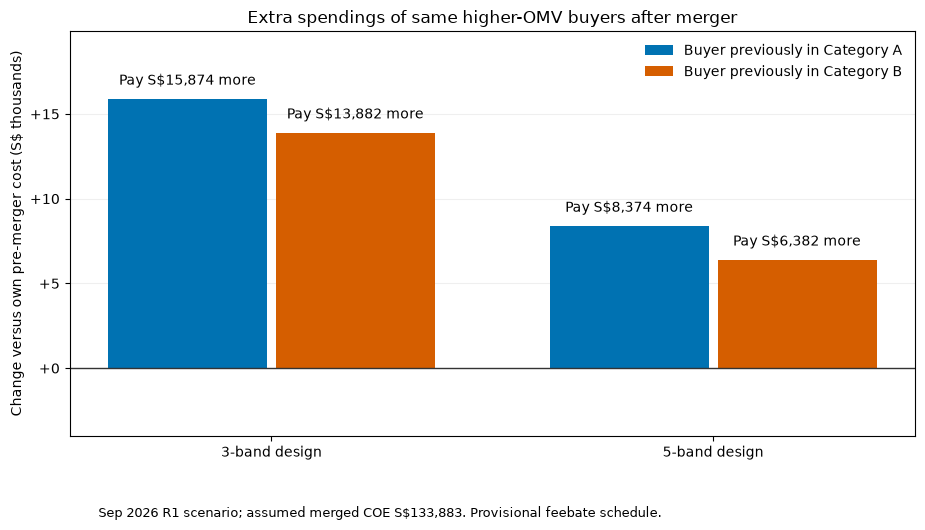

In [41]:
HIGH_OMV = float(sample_omv.quantile(0.60))
HIGH_NON_COE_COST = HIGH_OMV + (COMMON_NON_COE_BASIC_COST - SAME_OMV)
high_percentile = 100 * ((sample_omv < HIGH_OMV).sum()
    + 0.5*(sample_omv == HIGH_OMV).sum()) / len(sample_omv)
assert 50 < high_percentile <= 75
high_cost_records = []
for category in ['Category A', 'Category B']:
    old_coe = float(matched_round.loc[category, 'premium'])
    for design in ['3-band', '5-band']:
        surcharge = matched_feebate(high_percentile, design)
        before = HIGH_NON_COE_COST + old_coe
        after = HIGH_NON_COE_COST + matched_merged_coe + surcharge
        high_cost_records.append({'Original category': category, 'Design': design,
            'OMV': HIGH_OMV, 'Before cost': before, 'After cost': after,
            'Surcharge': surcharge, 'Extra spending': after-before})
high_cost_comparison = pd.DataFrame(high_cost_records)
display(high_cost_comparison.round(2))


fig, ax = plt.subplots(figsize=(11, 6))
for offset, category, color in [(-0.19, 'Category A', '#0072B2'), (0.19, 'Category B', '#D55E00')]:
    rows = high_cost_comparison.loc[high_cost_comparison['Original category'].eq(category)].set_index('Design').loc[['3-band', '5-band']]
    bars = ax.bar(np.arange(2)+offset, rows['Extra spending']/1000, width=0.36,
                  color=color, label=f'Buyer previously in {category}')
    for bar, amount in zip(bars, rows['Extra spending']):
        label = f'Save S${abs(amount):,.0f}' if amount < 0 else f'Pay S${amount:,.0f} more'
        ax.annotate(label, (bar.get_x()+bar.get_width()/2, bar.get_height()),
                    xytext=(0, -8 if amount < 0 else 8), textcoords='offset points',
                    ha='center', va='top' if amount < 0 else 'bottom', fontsize=10)
ax.axhline(0, color='#333333', linewidth=1)
ax.set_xticks(np.arange(2), ['3-band design', '5-band design'])
ax.set(title='Extra spendings of same higher-OMV buyers after merger', ylabel='Change versus own pre-merger cost (S$ thousands)')
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:+,.0f}'))
values = high_cost_comparison['Extra spending']/1000
ax.set_ylim(min(0, values.min())-4, max(0, values.max())+4)
ax.grid(axis='y', alpha=0.2); ax.set_axisbelow(True)
ax.legend(loc='lower right' if values.max() < 0 else 'upper right', frameon=False)
fig.text(0.5, 0.03, f'Sep 2026 R1 scenario; assumed merged COE S${matched_merged_coe:,.0f}. Provisional feebate schedule.', ha='center', fontsize=9)
fig.tight_layout(rect=[0.15, 0.1, 1, 0.9])

fig.savefig(FIGURE_DIR / '6_12_matched_higher_omv_costs.png',
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

**Interpretation:** Former A buyers pay about **S$15,874 / S$8,374 more** under three/five bands; former B buyers pay **S$13,882 / S$6,382 more**. Five bands soften the increase by S$7,500. Former A buyers face a larger increase because they lose their cheaper starting COE. Equal post-merger costs follow from the matched assumptions, rather than proving equal treatment or actual auction outcomes.

## 7. Key Findings & Recommendation

### Key findings

1. **Cat A's COE price advantage has weakened.** Between the previous and latest 24 exercises, average absolute separation fell from **14.95% to 4.26% of B**, and from **S$17,641 to S$5,224**. The latest 24-exercise average absolute percentage gap is the smallest in the supplied history (Figure 6.1).
2. **Convergence came through A becoming more expensive.** A's average premium rose **18.1%**, compared with **4.6%** for B. Similar premiums have not meant cheaper COEs for A buyers in these periods (Figure 6.2).
3. **The reported market mix shifted towards EVs and BYD.** Comparing June 2024-May 2025 with the preceding 12 months, pure-EV share gained **10.88 percentage points** and BYD **6.82 points**. Petrol lost **8.30 points** and Toyota **5.05 points** (Figures 6.3-6.4).
4. **Higher EV/BYD shares coincide more strongly with A pressure.** In June 2023-May 2025, prior-month EV correlations are **0.39 for A and 0.06 for B**; BYD correlations are **0.48 and 0.21**. Monthly-change correlations with A are near zero (**-0.05 and -0.04**), weakening a short-term explanatory claim (Figures 6.5-6.6).
5. **Listed vehicle values still differ in the September snapshot.** Median OMV is **S$27,175 for A** and **S$46,428 for B**, although the full ranges overlap. This is a single-month, unweighted comparison (Figure 6.7).
6. **Permanent convergence is not established.** Earlier close-gap periods later widened, and the selected forecasts allow for renewed separation. Their historical MAE improvements over the respective baselines are **17.84% for A** and **6.42% for B**, but model selection was exploratory and B's second six months exceed its evaluated horizon (Figure 6.8).
7. **Rebates alone do not guarantee savings after a merger.** A higher merged premium can absorb a rebate. Five bands reduce adjustment steps, but also reduce support for some groups compared with three bands (Figure 6.9).

### Recommendation

**Retain Categories A and B for now, while reviewing Cat A's weakened COE price advantage for buyers of lower-value cars.** Recent convergence raises a concern about price separation. The shift towards EVs and BYD provides additional market context, while the monthly-change results do not establish that this shift caused pressure increases or recent convergence. The OMV snapshot still shows different typical listed vehicle values. Neither the observed trends nor the forecasts establish permanent convergence, and the scenarios do not demonstrate that merging would improve buyer outcomes. This supports a cautious decision to retain the split at present.

**A merged auction with a five-band OMV feebate is a longer-term policy alternative.** It would link adjustments directly to vehicle value and make the steps smaller than under the illustrative three-band design. Its suitability depends on three conditions for adoption:

1. **Rebates cover the loss of Cat A's price advantage.** For intended rebate recipients currently using Cat A, the merged premium after the rebate should not exceed the premium under the retained split: $M-R\leq P_A$. The comparison should use prices for the same period and scenario.
2. **The distributional trade-off is acceptable.** Smaller steps should produce a preferable distribution of costs compared with three bands, while maintaining adequate protection for the 10th-35th OMV percentile group, whose rebate falls from S$15,000 to S$7,500.
3. **Protection and funding hold under higher merged premiums.** Registration-weighted outcomes should show how many intended beneficiaries save or pay more under stress scenarios, while surcharge receipts can sustainably fund rebates.

These are conditions for a future reform, not outcomes established by the present simulations. Retaining A/B today and treating five bands as a conditional future alternative is consistent with the strength and limits of the evidence.

## 8. Assumptions & Limitations

### Assumptions

- **Comparisons:** Exercises receive equal weight, percentage gaps use B's premium as the denominator, and absolute gaps measure separation regardless of direction. The 24-exercise window and 5% closeness threshold are analytical choices. OMV comparisons give each listed entry equal weight.
- **Missing observations:** Suspended bidding months are not filled. Unknown registration counts remain missing, and shares use reported counts only. Monthly lags follow the calendar; plot positions within a month indicate exercise order rather than exact auction dates.
- **Forecast inputs:** Future dates assume two exercises per month. A's EEAI indicator follows an assumed January 2021-December 2026 schedule; it is a model input, not a verified future policy statement. B's recursive paths hold future quota, bids and the other category's premium at their latest observed values.
- **Merger scenarios:** The quota-weighted premium and S$15,000 stress increase are assumptions, not estimated auction outcomes or confidence bounds. Band amounts remain fixed, with no estimated change in bidding behaviour. Percentile groups are not assigned actual registration shares or current COE categories. Sections 6.10-6.12 use percentiles of the unweighted listed-entry sample for hypothetical matched cars; these are not LTA's model-median, registration-based band thresholds. September R1 matched examples and October R2 break-even examples use different, explicitly stated reference exercises. Equal non-COE costs cancel in matched cost changes.

### Limits of the evidence

- **Historical comparisons:** COE coverage ends in October 2026, category definitions change within the history, and rolling windows overlap. Historical rankings describe this sample; they do not establish future persistence or policy causality.
- **Registration coverage:** 29,463 of 51,669 rows have unknown counts. Reported shares may therefore be incomplete. The file ends in May 2025, lacks model-level and COE-category information, and cannot explain the latest November 2025-October 2026 convergence window. The original EV and luxury-proxy summaries use different samples. The expanded A/B comparisons use a common June 2023-May 2025 window of 24 observations, but remain exploratory, serially dependent associations. Monthly changes check short-term co-movement, rather than identifying causal effects.
- **Market-mix comparisons:** Window shares require reported group subtotals in all 12 months, but unknown rows can remain within those subtotals. Makes/fuels without complete windows are not ranked. Share gains need not imply higher absolute registration counts, and share losses need not imply lower counts. Fuel and make groups overlap, and shares sum within a common market total, so associations are not independent effects. No significance tests or improvements in forecast performance are inferred.
- **OMV coverage:** The September 2026 report covers listed entries for models registered through local authorised distributors. It provides average OMVs without registration counts. Repeated labels are retained, parallel-import values may differ, and a single snapshot cannot measure market-wide buyer shares or changes in vehicle-value separation over time.
- **Forecast evaluation:** Historical tests were inspected during model development and informed selection. A has only two 24-exercise historical test paths; B's overlapping paths contain dependent errors. No prediction intervals or independent confirmation of forecast gains are available. B's rounds 13-24 exceed its evaluated horizon, and the combined A/B gap has not been validated as a separate forecast target.
- **Policy outcomes:** Individual bids, buyer incomes, registration-weighted model/category assignments and behavioural responses are unavailable. Vehicle-value groups are not household-income groups. Costs cover COE premiums and the assumed feebate, rather than total car ownership costs. No causal welfare effect, actual merged clearing price or sustainable feebate budget is estimated. Overall government revenue also depends on auction proceeds and other receipts and costs outside these calculations.

The analysis does not establish that EV adoption caused recent convergence, that convergence will persist, or that a merger or five-band design would improve affordability for every buyer.

## 9. Data Sources & Declarations

### Numerical datasets

| Dataset | Provider and acquisition | Local file | Coverage |
| --- | --- | --- | --- |
| COE bidding results and prices | LTA; supplied by SDS | `data/COEBiddingResultsPrices.csv` | Jan 2010-Oct 2026; 1,990 rows and 398 exercises |
| New car registrations by make | LTA; supplied by SDS | `data/NewRegistrationofCarsbyMake.csv` | Jan 2016-May 2025; 51,669 rows |
| Car cost update | LTA; team-provided CSV of the September report | `data/M032-Car_Cost_Update_Sep_2026.csv` | Sep 2026; 237 listed entries |

Original acquisition dates were not recorded. The additional OMV source is [LTA's September 2026 car cost report](https://onemotoring.lta.gov.sg/content/dam/onemotoring/Buying/Car_Cost_Update/M032-Car_Cost_Update.pdf), checked on **29 October 2026**. The published report link may be updated; calculations use the September snapshot stored in the local CSV. Its notes define the coverage and monthly average OMVs.

The COE file supports trends, forecasts and merged-price scenarios. Registrations support reported fuel/make share changes across June 2023-May 2024 and June 2024-May 2025, full-available-sample EV/luxury summaries, and matched June 2023-May 2025 A/B pressure associations. The OMV file supports the separate listed-value comparison; no registration-weighted OMV series is inferred. The three- and five-band schedules come from the team's workplan and are fully specified as illustrative inputs in Section 5.5, rather than official policy parameters.

### Policy references

- [LTA vehicle-statistics notes: historical Category A/B definitions](https://www.lta.gov.sg/content/dam/ltagov/who_we_are/statistics_and_publications/statistics/pdf/MVP02-1_New_Reg_by_COE.pdf).
- [LTA circular dated 8 March 2022: revision of the Category A maximum-power threshold for electric cars](https://onemotoring.lta.gov.sg/content/dam/onemotoring/pdf/Circulars%20to%20ESAs/2022/VRL_04_2022.pdf).

These documents support the historical policy context in Section 4 and were checked on **29 October 2026**. They are not evidence of causal price effects or confirmation of future policy assumptions.

### Software references

- [scikit-learn: RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor).
- [LightGBM: LGBMRegressor](https://lightgbm.readthedocs.io/en/latest/pythonapi/lightgbm.LGBMRegressor.html).
- [skforecast 0.26.0: metrics and backtesting](https://skforecast.org/0.26.0/user_guides/metrics).

### AI tool use

OpenAI Codex assisted with data validation, implementation, exploratory checks, forecasting integration, visualisations and documentation. The notebook records the analytical choices, numerical results and limitations; the policy recommendation reflects the team’s interpretation of that evidence.

### Reproducibility

The notebook runs on **Python 3.14** with the package versions in `requirements.txt`, using relative paths from the repository root. Random Forest uses seed 42 and LightGBM seed 123; plot jitter also uses a fixed seed. All cleaning, model fitting, historical evaluation and scenario calculations are included in this notebook. The analysis reads the three local CSV files without live API calls or saved prediction inputs. Section 6 generates 13 figures (including two in Section 6.8) and saves 300-dpi PNG copies in `figures/`.